<a href="https://colab.research.google.com/github/harshalichowdhary-design/NyayaRAG/blob/main/05_NyayaRAG_Generation_and_Evaluation_Qwen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYAYaRAG — Evidence-Grounded Answer Generation and Safe Abstention

## Pilot Evaluation for RQ3 and RQ4

This notebook implements the generation and abstention components of the
NYAYaRAG framework using a stronger open instruction-tuned language model
running directly on a Google Colab GPU.

The notebook evaluates:

- **RQ3 — Evidence-Grounded Answer Generation:**  
  How accurately does NYAYaRAG generate legally correct, complete, faithful,
  and citation-grounded answers from retrieved Supreme Court judgments?

- **RQ4 — Safe Abstention:**  
  Can NYAYaRAG reliably abstain when the retrieved evidence is insufficient,
  thereby reducing unsupported or hallucinated legal answers?

The retrieval component is fixed as the previously selected **Hybrid
retriever**, and the Top-5 retrieved chunks for each pilot question are used as
the sole evidence supplied to the generator.


In [ ]:
# ============================================================
# MOUNT GOOGLE DRIVE AND DEFINE PROJECT ROOT
# ============================================================

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/NyayaRAG")

assert PROJECT_ROOT.exists(), (
    f"Project root not found: {PROJECT_ROOT}"
)

print("=" * 72)
print("NYAYaRAG PROJECT INITIALISATION")
print("=" * 72)
print(f"Project root : {PROJECT_ROOT}")
print("Status       : READY")

Mounted at /content/drive
NYAYaRAG PROJECT INITIALISATION
Project root : /content/drive/MyDrive/NyayaRAG
Status       : READY


In [ ]:
# ============================================================
# INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install -U transformers accelerate bitsandbytes sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 23.4 MB/s eta 0:00:00


In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import gc
import json
import random

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    pipeline,
)

print("=" * 72)
print("LIBRARIES IMPORTED")
print("=" * 72)

print(f"PyTorch        : {torch.__version__}")
print(f"Transformers   : imported")
print(f"CUDA Available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")

LIBRARIES IMPORTED
PyTorch        : 2.11.0+cu128
Transformers   : imported
CUDA Available : True
GPU            : Tesla T4


In [ ]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 72)
print("REPRODUCIBILITY")
print("=" * 72)

print(f"Random seed : {SEED}")

REPRODUCIBILITY
Random seed : 42


In [ ]:
# ============================================================
# GPU MEMORY CHECK
# ============================================================

assert torch.cuda.is_available(), (
    "Please switch Colab to a GPU runtime."
)

gpu_properties = torch.cuda.get_device_properties(0)

print("=" * 72)
print("GPU INFORMATION")
print("=" * 72)

print(f"GPU                : {gpu_properties.name}")
print(f"Total Memory (GB)  : {gpu_properties.total_memory/1024**3:.2f}")

GPU INFORMATION
GPU                : Tesla T4
Total Memory (GB)  : 14.56


## 2. Selection of the Colab-Based Generation Model

The generation component is implemented using
`Qwen/Qwen3-4B-Instruct-2507`, an open instruction-tuned language model.

The model is loaded in four-bit quantised form to operate within the memory
constraints of the Tesla T4 GPU while retaining substantially greater
instruction-following capacity than the lightweight local model tested during
the initial Ollama pilot.

The generation model is treated as a fixed component of the NYAYaRAG pipeline.
It is not fine-tuned during this experiment. All pilot questions are processed
using the same model, retrieval depth, prompt, temperature, and decoding
configuration.

In [ ]:
# ============================================================
# DEFINE COLAB GENERATION MODEL CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"

GENERATION_TEMPERATURE = 0.0
GENERATION_SEED = 42
MAX_NEW_TOKENS = 600

USE_4BIT_QUANTISATION = True

print("=" * 72)
print("GENERATION MODEL CONFIGURATION")
print("=" * 72)
print(f"Model ID              : {MODEL_ID}")
print(f"Four-bit quantisation : {USE_4BIT_QUANTISATION}")
print(f"Temperature           : {GENERATION_TEMPERATURE}")
print(f"Seed                  : {GENERATION_SEED}")
print(f"Maximum new tokens    : {MAX_NEW_TOKENS}")

GENERATION MODEL CONFIGURATION
Model ID              : Qwen/Qwen3-4B-Instruct-2507
Four-bit quantisation : True
Temperature           : 0.0
Seed                  : 42
Maximum new tokens    : 600


In [ ]:
# ============================================================
# IMPORT MODEL-LOADING COMPONENTS
# ============================================================

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig
)

print("Model-loading components imported successfully.")

Model-loading components imported successfully.


In [ ]:
# ============================================================
# DEFINE FOUR-BIT QUANTISATION
# ============================================================

quantisation_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("=" * 72)
print("QUANTISATION CONFIGURATION")
print("=" * 72)
print("Load in 4-bit        : True")
print("Quantisation type    : NF4")
print("Compute dtype        : float16")
print("Double quantisation  : Enabled")

QUANTISATION CONFIGURATION
Load in 4-bit        : True
Quantisation type    : NF4
Compute dtype        : float16
Double quantisation  : Enabled


In [ ]:
# ============================================================
# LOAD QWEN TOKENIZER AND FOUR-BIT MODEL
# ============================================================

import time

load_started = time.perf_counter()

print("=" * 72)
print("LOADING GENERATION MODEL")
print("=" * 72)
print(f"Model : {MODEL_ID}")
print("This may take several minutes on the first run.\n")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantisation_config,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

model.eval()

load_elapsed = time.perf_counter() - load_started

print("\n" + "=" * 72)
print("MODEL LOADING COMPLETE")
print("=" * 72)
print(f"Tokenizer class : {type(tokenizer).__name__}")
print(f"Model class     : {type(model).__name__}")
print(f"Primary device  : {model.device}")
print(f"Load time       : {load_elapsed:.2f} seconds")

LOADING GENERATION MODEL
Model : Qwen/Qwen3-4B-Instruct-2507
This may take several minutes on the first run.



config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]


MODEL LOADING COMPLETE
Tokenizer class : Qwen2Tokenizer
Model class     : Qwen3ForCausalLM
Primary device  : cuda:0
Load time       : 210.42 seconds


In [ ]:
# ============================================================
# VALIDATE MODEL PLACEMENT AND GPU MEMORY
# ============================================================

assert tokenizer is not None, "Tokenizer failed to load."
assert model is not None, "Model failed to load."

allocated_gb = torch.cuda.memory_allocated(0) / 1024**3
reserved_gb = torch.cuda.memory_reserved(0) / 1024**3
total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3

print("=" * 72)
print("MODEL AND GPU VALIDATION")
print("=" * 72)
print(f"Model ID             : {MODEL_ID}")
print(f"Model training mode  : {model.training}")
print(f"GPU memory allocated : {allocated_gb:.2f} GB")
print(f"GPU memory reserved  : {reserved_gb:.2f} GB")
print(f"Total GPU memory     : {total_gb:.2f} GB")
print("Validation status    : PASSED")

MODEL AND GPU VALIDATION
Model ID             : Qwen/Qwen3-4B-Instruct-2507
Model training mode  : False
GPU memory allocated : 2.49 GB
GPU memory reserved  : 2.54 GB
Total GPU memory     : 14.56 GB
Validation status    : PASSED


## 3. Load and Validate the Pilot Benchmark and Hybrid Retrieval Evidence

The pilot benchmark contains ten legal questions contributed by judicial
officers. For each question, the previously selected Hybrid retriever has
returned the Top-5 judgment chunks.

The generation model will receive only:

- the legal question; and
- the corresponding Top-5 retrieved chunks.

The human answerability labels will be retained separately for later evaluation
of safe abstention and will not be disclosed to the generator.

In [ ]:
# ============================================================
# LOAD PILOT QUESTIONS AND HYBRID RETRIEVAL RESULTS
# ============================================================

import pandas as pd
from pathlib import Path

PILOT_QUESTIONS_FILE = (
    PROJECT_ROOT
    / "benchmark"
    / "final"
    / "pilot_questions.csv"
)

HYBRID_RETRIEVAL_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "retrieval"
    / "hybrid_pilot_retrieval.csv"
)

assert PILOT_QUESTIONS_FILE.exists(), (
    f"Pilot-question file not found:\n{PILOT_QUESTIONS_FILE}"
)

assert HYBRID_RETRIEVAL_FILE.exists(), (
    f"Hybrid retrieval file not found:\n{HYBRID_RETRIEVAL_FILE}"
)

pilot_questions = pd.read_csv(
    PILOT_QUESTIONS_FILE
)

hybrid_retrieval = pd.read_csv(
    HYBRID_RETRIEVAL_FILE
)

print("=" * 76)
print("PILOT DATA LOADING")
print("=" * 76)
print(f"Pilot questions loaded : {len(pilot_questions)}")
print(f"Hybrid retrieval rows  : {len(hybrid_retrieval)}")
print(f"Question file          : {PILOT_QUESTIONS_FILE.name}")
print(f"Retrieval file         : {HYBRID_RETRIEVAL_FILE.name}")

PILOT DATA LOADING
Pilot questions loaded : 10
Hybrid retrieval rows  : 50
Question file          : pilot_questions.csv
Retrieval file         : hybrid_pilot_retrieval.csv


In [ ]:
# ============================================================
# STANDARDISE COLUMN NAMES
# ============================================================

def standardise_columns(dataframe: pd.DataFrame) -> pd.DataFrame:
    """
    Return a copy with lowercase snake-case column names.
    """

    result = dataframe.copy()

    result.columns = (
        result.columns
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )

    return result


pilot_questions = standardise_columns(
    pilot_questions
)

hybrid_retrieval = standardise_columns(
    hybrid_retrieval
)

hybrid_retrieval = hybrid_retrieval.rename(
    columns={
        "global_chunk_id": "chunk_id",
        "rrf_score": "retrieval_score",
        "rank": "retrieval_rank"
    }
)

print("Pilot-question columns:")
print(pilot_questions.columns.tolist())

print("\nHybrid-retrieval columns:")
print(hybrid_retrieval.columns.tolist())

Pilot-question columns:
['question_id', 'contributor', 'experience', 'question_no', 'question', 'word_count']

Hybrid-retrieval columns:
['question_id', 'question', 'chunk_id', 'judgment_id', 'case_title', 'local_chunk_id', 'bm25_rank', 'e5_rank', 'retrieval_score', 'chunk_text', 'retrieval_rank']


In [ ]:
# ============================================================
# VALIDATE PILOT BENCHMARK AND HYBRID RETRIEVAL
# ============================================================

required_question_columns = {
    "question_id",
    "question"
}

required_retrieval_columns = {
    "question_id",
    "question",
    "chunk_id",
    "judgment_id",
    "case_title",
    "chunk_text",
    "retrieval_rank",
    "retrieval_score"
}

missing_question_columns = (
    required_question_columns
    - set(pilot_questions.columns)
)

missing_retrieval_columns = (
    required_retrieval_columns
    - set(hybrid_retrieval.columns)
)

assert not missing_question_columns, (
    "Missing pilot-question columns: "
    f"{sorted(missing_question_columns)}"
)

assert not missing_retrieval_columns, (
    "Missing Hybrid retrieval columns: "
    f"{sorted(missing_retrieval_columns)}"
)

assert len(pilot_questions) == 10, (
    f"Expected 10 pilot questions, found {len(pilot_questions)}."
)

assert pilot_questions["question_id"].is_unique, (
    "Duplicate question IDs were found."
)

assert len(hybrid_retrieval) == 50, (
    f"Expected 50 retrieval rows, found {len(hybrid_retrieval)}."
)

chunks_per_question = (
    hybrid_retrieval
    .groupby("question_id")
    .size()
)

assert chunks_per_question.eq(5).all(), (
    "Every pilot question must have exactly five retrieved chunks."
)

benchmark_ids = set(
    pilot_questions["question_id"]
)

retrieval_ids = set(
    hybrid_retrieval["question_id"]
)

assert benchmark_ids == retrieval_ids, (
    "Question IDs in the benchmark and retrieval file do not match."
)

empty_questions = (
    pilot_questions["question"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

empty_chunks = (
    hybrid_retrieval["chunk_text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

assert empty_questions == 0
assert empty_chunks == 0

print("=" * 76)
print("PILOT BENCHMARK AND RETRIEVAL VALIDATION")
print("=" * 76)
print(f"Pilot questions          : {len(pilot_questions)}")
print(f"Unique question IDs      : {pilot_questions['question_id'].nunique()}")
print(f"Hybrid retrieval rows    : {len(hybrid_retrieval)}")
print(f"Chunks per question      : {chunks_per_question.min()}–{chunks_per_question.max()}")
print(f"Empty questions          : {empty_questions}")
print(f"Empty retrieved chunks   : {empty_chunks}")
print("Benchmark–retrieval match: Yes")
print("Validation status        : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question"
        ]
    ]
)

PILOT BENCHMARK AND RETRIEVAL VALIDATION
Pilot questions          : 10
Unique question IDs      : 10
Hybrid retrieval rows    : 50
Chunks per question      : 5–5
Empty questions          : 0
Empty retrieved chunks   : 0
Benchmark–retrieval match: Yes
Validation status        : PASSED


,question_id,question
0,RAW001,Under what circumstances can delay in lodging ...
1,RAW002,Can a conviction be sustained solely on the te...
2,RAW004,When may a court interfere with an arbitral aw...
3,RAW005,What are the conditions for granting anticipat...
4,RAW006,Under what circumstances can a court permit am...
5,RAW007,What are the essential ingredients required to...
6,RAW010,What are the mandatory preconditions for exerc...
7,RAW012,Can a civil suit for damages on account of mur...
8,RAW015,How can a magistrate certify the correctness o...
9,RAW017,Can an authorised signatory be convicted under...


## 4. Establish Expert Ground-Truth Answerability Labels

Before answer generation, each pilot question is assigned an expert
ground-truth answerability label based on the sufficiency of the Top-5 Hybrid
retrieval evidence.

The labels are:

- **`answerable`** — the retrieved evidence is sufficient to formulate a
  reliable legal answer; and
- **`insufficient_evidence`** — the retrieved evidence does not adequately
  address the central legal issue and the generator should abstain.

These labels were determined independently through legal review of the
retrieved chunks. They are retained solely for subsequent RQ4 evaluation and
will not be supplied to the generation model.

In [ ]:
# ============================================================
# RECORD EXPERT GROUND-TRUTH ANSWERABILITY LABELS
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "answerable",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

print("=" * 76)
print("EXPERT ANSWERABILITY LABELS")
print("=" * 76)

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)

EXPERT ANSWERABILITY LABELS


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,answerable
9,RAW017,Can an authorised signatory be convicted under...,answerable


In [ ]:
# ============================================================
# VALIDATE EXPERT ANSWERABILITY LABELS
# ============================================================

allowed_answerability_labels = {
    "answerable",
    "insufficient_evidence"
}

assert pilot_questions["answerability_label"].notna().all(), (
    "One or more pilot questions do not have an answerability label."
)

unexpected_labels = (
    set(pilot_questions["answerability_label"])
    - allowed_answerability_labels
)

assert not unexpected_labels, (
    f"Unexpected answerability labels: {sorted(unexpected_labels)}"
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

assert answerability_counts.get("answerable", 0) == 8, (
    "Expected eight answerable pilot questions."
)

assert answerability_counts.get("insufficient_evidence", 0) == 2, (
    "Expected two insufficient-evidence pilot questions."
)

print("=" * 76)
print("ANSWERABILITY GROUND-TRUTH VALIDATION")
print("=" * 76)
print(f"Questions labelled       : {len(pilot_questions)}")
print(
    f"Answerable               : "
    f"{answerability_counts.get('answerable', 0)}"
)
print(
    f"Insufficient evidence    : "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Labels disclosed to model: No")
print("Validation status        : PASSED")

ANSWERABILITY GROUND-TRUTH VALIDATION
Questions labelled       : 10
Answerable               : 8
Insufficient evidence    : 2
Labels disclosed to model: No
Validation status        : PASSED


In [ ]:
# ============================================================
# INSTALL GOOGLE GEN AI SDK
# ============================================================

!pip -q install -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.6/258.6 kB 22.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.56.2 which is incompatible.


In [ ]:
# ============================================================
# INITIALISE GEMINI
# ============================================================

from google.colab import userdata
from google import genai

API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=API_KEY)

print("=" * 72)
print("GEMINI INITIALISATION")
print("=" * 72)
print("Status : SUCCESS")

GEMINI INITIALISATION
Status : SUCCESS


In [ ]:
# ============================================================
# LIST AVAILABLE GEMINI MODELS
# ============================================================

for model in client.models.list():
    print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-pro-preview
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/gemini-3.1-flash-

In [ ]:
MODEL_NAME = "models/gemini-3.5-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Reply with only the word OK."
)

print(response.text)

OK


In [ ]:
# ============================================================
# NYAYaRAG GENERATION MODEL
# ============================================================

MODEL_NAME = "models/gemini-3.5-flash"

print("=" * 72)
print("GENERATION MODEL")
print("=" * 72)
print(f"Model : {MODEL_NAME}")
print("Status: READY")

GENERATION MODEL
Model : models/gemini-3.5-flash
Status: READY


## 5. Evidence-Grounded Prompt Engineering

The generation component of NYAYaRAG is designed to operate as an
evidence-grounded legal research assistant rather than a general-purpose
language model.

To minimise hallucinations and improve trustworthiness, the generator is
explicitly instructed to:

- rely exclusively on the retrieved Supreme Court judgment excerpts;
- avoid using external legal knowledge;
- support legal propositions with the retrieved evidence;
- abstain whenever the supplied evidence is insufficient; and
- produce a structured response suitable for automatic evaluation.

The same prompt is used for every pilot question to ensure methodological
consistency and reproducibility.



In [ ]:
# ============================================================
# NYAYaRAG SYSTEM PROMPT
# ============================================================

SYSTEM_PROMPT = """
You are NYAYaRAG, an evidence-grounded legal research assistant.

Your task is to answer legal questions ONLY from the supplied Supreme Court
judgment excerpts.

You must follow these rules strictly.

1. Use ONLY the supplied evidence.

2. Do NOT use outside legal knowledge.

3. Do NOT infer facts that are not supported by the evidence.

4. Every legal proposition must be supported by one or more evidence
sources.

5. If the supplied evidence is insufficient to answer the legal question
reliably, you MUST abstain.

6. Never fabricate legal principles, statutes, cases or citations.

Return your response in EXACTLY the following format.

DECISION:
ANSWER
or
INSUFFICIENT_EVIDENCE

ANSWER:
<your legal answer>

CITATIONS:
S1
or
S1, S2
or
NONE

REASON:
Briefly explain why the evidence was sufficient or insufficient.
"""

print("=" * 72)
print("SYSTEM PROMPT INITIALISED")
print("=" * 72)
print(SYSTEM_PROMPT)

SYSTEM PROMPT INITIALISED

You are NYAYaRAG, an evidence-grounded legal research assistant.

Your task is to answer legal questions ONLY from the supplied Supreme Court
judgment excerpts.

You must follow these rules strictly.

1. Use ONLY the supplied evidence.

2. Do NOT use outside legal knowledge.

3. Do NOT infer facts that are not supported by the evidence.

4. Every legal proposition must be supported by one or more evidence
sources.

5. If the supplied evidence is insufficient to answer the legal question
reliably, you MUST abstain.

6. Never fabricate legal principles, statutes, cases or citations.

Return your response in EXACTLY the following format.

DECISION:
ANSWER
or
INSUFFICIENT_EVIDENCE

ANSWER:
<your legal answer>

CITATIONS:
S1
or
S1, S2
or
NONE

REASON:
Briefly explain why the evidence was sufficient or insufficient.



## 6. Construction of the Evidence Package

For every legal question, the Hybrid retriever has already produced the
Top-5 most relevant judgment chunks.

These chunks are combined into a single evidence package and supplied to the
generation model.

Each retrieved chunk is assigned a stable identifier (`S1`–`S5`), enabling the
generation model to explicitly reference the supporting evidence when answering
the legal question.

In [ ]:
# ============================================================
# BUILD EVIDENCE PACKAGE
# ============================================================

def build_evidence_package(question_id):
    """
    Build the evidence package supplied to Gemini.
    """

    rows = (
        hybrid_retrieval
        .query("question_id == @question_id")
        .sort_values("retrieval_rank")
    )

    evidence = []

    for i, (_, row) in enumerate(rows.iterrows(), start=1):

        evidence.append(
f"""
==================================================
SOURCE {i}
==================================================

Case Title:
{row.case_title}

Official Citation:
{row.judgment_id}

Retrieval Rank:
{row.retrieval_rank}

Evidence Excerpt:
{row.chunk_text}
"""
        )

    return "\n".join(evidence)

In [ ]:
# ============================================================
# BUILD USER PROMPT
# ============================================================

def build_user_prompt(question_id):

    question = (
        pilot_questions
        .loc[
            pilot_questions.question_id == question_id,
            "question"
        ]
        .iloc[0]
    )

    evidence = build_evidence_package(question_id)

    return f"""
LEGAL QUESTION

{question}


RETRIEVED SUPREME COURT JUDGMENTS

{evidence}


INSTRUCTIONS

Answer ONLY from the retrieved judgments.

Do NOT use any legal knowledge outside these judgments.

Where multiple judgments support the same proposition,
synthesise them into a single legal answer.

Write in clear legal prose.

Do NOT copy the evidence verbatim.

Whenever you rely on a judgment,
cite its official case title and citation.

If the evidence is insufficient,
state that the evidence is insufficient.

Do NOT mention SOURCE 1, SOURCE 2, etc.
Those identifiers are only for internal retrieval.
"""

In [ ]:
# ============================================================
# INSPECT FIRST PROMPT
# ============================================================

sample_prompt = build_user_prompt("RAW001")

print(sample_prompt[:6000])


LEGAL QUESTION

Under what circumstances can delay in lodging an FIR affect the prosecution case?


RETRIEVED SUPREME COURT JUDGMENTS


SOURCE 1

Case Title:
SHENTO VARGHESE versus JULFIKAR HUSEN & ORS.

Official Citation:
[2024] 6 S.C.R. 409

Retrieval Rank:
1

Evidence Excerpt:
provides that ‘if, from information received or otherwise, an officer in charge of a police station has reason to suspect the commission of an offence……he shall forthwith send a report of the same to a Magistrate’. As in the case of Section 102(3) Cr.P.C., Section 157 Cr.P.C. does not provide for any consequence in the event there is failure to promptly comply with the reporting obligation. It would be helpful to understand how this Court has elucidated on the effect of such non-compliance in the context of Section 157 Cr.P.C. since the provision is nearly pari materia with Section 102(3). 16. It is now too well settled that delay in registration of FIR is no ground for quashing of the FIR itself.20 It follow

In [ ]:
# ============================================================
# GENERATE FIRST NYAYaRAG ANSWER
# ============================================================

prompt = build_user_prompt("RAW001")

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=[
        SYSTEM_PROMPT,
        prompt
    ]
)

print(response.text)

DECISION:
ANSWER

ANSWER:
Under Indian jurisprudence, the circumstances and effects of a delay in lodging an FIR are governed by the following principles:

1. **No Automatic Adverse Effect:** Mere delay in lodging or registering an FIR does not *ipso facto* affect the merits of the prosecution's case, nor does it constitute a valid ground for quashing the FIR itself (*Anil Bhavarlal Jain & Anr. versus The State of Maharashtra & Ors.*, *Shento Varghese versus Julfikar Husen & Ors.*).
2. **Requirement of a Logical and Convincing Explanation:** While delay can be overlooked if there is a valid reason, the explanation provided by the prosecution must be logical and convincing. If the explanation for the delay is fanciful, unconvincing, or contradicted by established facts—such as claiming the complainant party was delayed due to fear of threats after the safety of the victim had already been secured—the court will not overlook the delay (*Gaurav Maini versus The State of Haryana*). 
3. **E

## 7. Final Prompt and Batch Generation

Following single-question pilot testing, the generation prompt was simplified
to avoid repetitive decision and explanation fields.

For answerable questions, the model must provide:

1. a concise legal answer in paragraph form; and
2. the Supreme Court authorities relied upon.

For questions where the retrieved evidence is insufficient, the model must
return the prescribed abstention statement and must not attempt an answer.

The prompt, model, retrieval depth, and generation procedure are frozen before
batch generation to prevent question-specific prompt optimisation.

In [ ]:
# ============================================================
# FREEZE FINAL NYAYaRAG GENERATION PROMPT
# ============================================================

FINAL_SYSTEM_PROMPT = """
You are NYAYaRAG, an evidence-grounded legal research assistant.

Answer the legal question ONLY from the supplied excerpts of Supreme Court
judgments.

MANDATORY RULES

1. Do not use outside legal knowledge, memory, assumptions, or information
   not contained in the supplied evidence.

2. State only legal propositions that are supported by the supplied judgment
   excerpts.

3. Write the answer as one or more concise legal paragraphs. Avoid numbered
   lists unless they are necessary for clarity.

4. Whenever relying on a judgment, cite its case title and official citation
   exactly as supplied.

5. Do not cite internal retrieval labels such as SOURCE 1, S1, or S2 in the
   legal answer.

6. Do not treat counsel's submissions, allegations, or lower-court reasoning
   as a holding of the Supreme Court unless the excerpt clearly adopts it.

7. Do not invent or alter case names, citations, statutory provisions,
   quotations, facts, procedural history, or holdings.

8. If the supplied evidence does not reliably answer the central legal issue,
   do not guess. Return the prescribed abstention response.

Use exactly one of the following two formats.

FORMAT A — SUFFICIENT EVIDENCE

LEGAL ANSWER

<Substantive legal answer in one or more concise paragraphs, containing
case-title and official-citation references where relied upon.>

AUTHORITIES RELIED UPON

<List each relied-upon judgment once, using its case title and official
citation.>


FORMAT B — INSUFFICIENT EVIDENCE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this
question reliably.

AUTHORITIES RELIED UPON

None

Do not add any other heading, decision label, reason, preface, or conclusion.
""".strip()


MODEL_NAME = "models/gemini-3.5-flash"
MAX_OUTPUT_TOKENS = 1200

print("=" * 76)
print("FINAL GENERATION CONFIGURATION")
print("=" * 76)
print(f"Model                : {MODEL_NAME}")
print("Prompt status        : FROZEN")
print("Retrieval depth      : Top-5 Hybrid chunks")
print(f"Maximum output tokens: {MAX_OUTPUT_TOKENS}")
print("Temperature          : Model default")

FINAL GENERATION CONFIGURATION
Model                : models/gemini-3.5-flash
Prompt status        : FROZEN
Retrieval depth      : Top-5 Hybrid chunks
Maximum output tokens: 1200
Temperature          : Model default


In [ ]:
# ============================================================
# BUILD FINAL QUESTION-SPECIFIC USER PROMPT
# ============================================================

def build_final_user_prompt(question_id: str) -> str:
    """
    Build the question-specific prompt without exposing the
    expert answerability label.
    """

    question_rows = pilot_questions.loc[
        pilot_questions["question_id"].eq(question_id),
        "question"
    ]

    if len(question_rows) != 1:
        raise ValueError(
            f"Expected one question for {question_id}, "
            f"found {len(question_rows)}."
        )

    question = question_rows.iloc[0]
    evidence = build_evidence_package(question_id)

    return f"""
LEGAL QUESTION

{question}


RETRIEVED SUPREME COURT JUDGMENT EXCERPTS

{evidence}


TASK

Answer the legal question in accordance with the mandatory rules and one of
the two permitted response formats.
""".strip()

In [ ]:
# ============================================================
# PARSE GEMINI RESPONSE
# ============================================================

import re


ABSTENTION_TEXT = (
    "The retrieved judgments do not provide sufficient evidence "
    "to answer this question reliably."
)


def parse_generation_response(response_text: str) -> dict:
    """
    Extract the legal answer and authorities from the fixed text format.
    """

    text = str(response_text or "").strip()

    answer_match = re.search(
        r"LEGAL ANSWER\s*(.*?)\s*AUTHORITIES RELIED UPON",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    authorities_match = re.search(
        r"AUTHORITIES RELIED UPON\s*(.*)$",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    legal_answer = (
        answer_match.group(1).strip()
        if answer_match
        else ""
    )

    authorities_text = (
        authorities_match.group(1).strip()
        if authorities_match
        else ""
    )

    normalised_answer = " ".join(
        legal_answer.lower().split()
    )

    normalised_abstention = " ".join(
        ABSTENTION_TEXT.lower().split()
    )

    model_decision = (
        "INSUFFICIENT_EVIDENCE"
        if normalised_answer == normalised_abstention
        else "ANSWER"
    )

    format_valid = bool(
        answer_match
        and authorities_match
        and legal_answer
        and authorities_text
    )

    return {
        "model_decision": model_decision,
        "generated_answer": legal_answer,
        "authorities_text": authorities_text,
        "format_valid": format_valid
    }

In [ ]:
# ============================================================
# GENERATE ANSWERS FOR ALL 10 PILOT QUESTIONS
# ============================================================

import time
from datetime import datetime, timezone

from google.genai import types
from tqdm.auto import tqdm


GENERATION_OUTPUT_DIR = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
)

GENERATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GENERATION_RESULTS_FILE = (
    GENERATION_OUTPUT_DIR
    / "gemini35_pilot_generation_results.csv"
)


def generate_one_answer(
    question_id: str,
    max_retries: int = 3
) -> dict:
    """
    Generate and parse one evidence-grounded legal answer.
    """

    user_prompt = build_final_user_prompt(question_id)

    last_error = None

    for attempt in range(1, max_retries + 1):

        try:
            started = time.perf_counter()

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=user_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=FINAL_SYSTEM_PROMPT,
                    max_output_tokens=MAX_OUTPUT_TOKENS,
                    response_mime_type="text/plain"
                )
            )

            elapsed_seconds = time.perf_counter() - started
            raw_response = str(response.text or "").strip()

            parsed = parse_generation_response(
                raw_response
            )

            return {
                "generation_status": "success",
                "question_id": question_id,
                "model_name": MODEL_NAME,
                "raw_model_response": raw_response,
                "model_decision": parsed["model_decision"],
                "generated_answer": parsed["generated_answer"],
                "authorities_text": parsed["authorities_text"],
                "format_valid": parsed["format_valid"],
                "elapsed_seconds": round(elapsed_seconds, 3),
                "attempts": attempt,
                "generated_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "error_message": ""
            }

        except Exception as error:
            last_error = error

            if attempt < max_retries:
                time.sleep(5 * attempt)

    return {
        "generation_status": "failure",
        "question_id": question_id,
        "model_name": MODEL_NAME,
        "raw_model_response": "",
        "model_decision": "",
        "generated_answer": "",
        "authorities_text": "",
        "format_valid": False,
        "elapsed_seconds": None,
        "attempts": max_retries,
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "error_message": str(last_error)
    }


generation_records = []

for question_id in tqdm(
    pilot_questions["question_id"],
    desc="Generating pilot answers"
):
    record = generate_one_answer(question_id)
    generation_records.append(record)

    # Save progress after every question.
    pd.DataFrame(generation_records).to_csv(
        GENERATION_RESULTS_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    # Conservative delay to reduce rate-limit risk.
    time.sleep(2)


gemini_generation_results = pd.DataFrame(
    generation_records
)

print("\n" + "=" * 76)
print("PILOT GENERATION COMPLETE")
print("=" * 76)
print(f"Questions processed : {len(gemini_generation_results)}")
print(
    "Successful          : "
    f"{gemini_generation_results['generation_status'].eq('success').sum()}"
)
print(
    "Failed              : "
    f"{gemini_generation_results['generation_status'].eq('failure').sum()}"
)
print(f"Saved to            : {GENERATION_RESULTS_FILE}")

Generating pilot answers:   0%|          | 0/10 [00:00<?, ?it/s]


PILOT GENERATION COMPLETE
Questions processed : 10
Successful          : 10
Failed              : 0
Saved to            : /content/drive/MyDrive/NyayaRAG/evaluation/pilot/generation_gemini/gemini35_pilot_generation_results.csv


In [ ]:
# ============================================================
# VALIDATE PILOT GENERATION RESULTS
# ============================================================

assert len(gemini_generation_results) == 10, (
    "Expected ten pilot generation records."
)

assert gemini_generation_results["question_id"].is_unique, (
    "Duplicate question IDs were found."
)

successful_mask = (
    gemini_generation_results["generation_status"]
    .eq("success")
)

failed_count = (~successful_mask).sum()

valid_decisions = {
    "ANSWER",
    "INSUFFICIENT_EVIDENCE"
}

invalid_decisions = gemini_generation_results.loc[
    successful_mask
    & ~gemini_generation_results["model_decision"].isin(
        valid_decisions
    )
]

empty_successful_answers = gemini_generation_results.loc[
    successful_mask
    & gemini_generation_results["generated_answer"]
    .fillna("")
    .str.strip()
    .eq("")
]

print("=" * 76)
print("PILOT GENERATION VALIDATION")
print("=" * 76)
print(f"Records loaded          : {len(gemini_generation_results)}")
print(f"Successful generations  : {successful_mask.sum()}")
print(f"Failed generations      : {failed_count}")
print(
    "Valid output format     : "
    f"{gemini_generation_results['format_valid'].sum()}/10"
)
print(f"Invalid decisions       : {len(invalid_decisions)}")
print(f"Empty successful answers: {len(empty_successful_answers)}")

if failed_count == 0 and invalid_decisions.empty and empty_successful_answers.empty:
    print("Validation status       : PASSED")
else:
    print("Validation status       : REVIEW REQUIRED")

display(
    gemini_generation_results[
        [
            "question_id",
            "generation_status",
            "model_decision",
            "format_valid",
            "elapsed_seconds"
        ]
    ]
)

PILOT GENERATION VALIDATION
Records loaded          : 10
Successful generations  : 10
Failed generations      : 0
Valid output format     : 5/10
Invalid decisions       : 0
Empty successful answers: 5
Validation status       : REVIEW REQUIRED


,question_id,generation_status,model_decision,format_valid,elapsed_seconds
0,RAW001,success,INSUFFICIENT_EVIDENCE,True,4.656
1,RAW002,success,ANSWER,False,4.423
2,RAW004,success,ANSWER,False,4.614
3,RAW005,success,INSUFFICIENT_EVIDENCE,True,2.852
4,RAW006,success,ANSWER,False,4.582
5,RAW007,success,ANSWER,False,4.216
6,RAW010,success,INSUFFICIENT_EVIDENCE,True,3.238
7,RAW012,success,INSUFFICIENT_EVIDENCE,True,3.970
8,RAW015,success,INSUFFICIENT_EVIDENCE,True,2.172
9,RAW017,success,ANSWER,False,4.249


In [ ]:
# ============================================================
# INSPECT ALL RAW GEMINI RESPONSES
# ============================================================

for _, row in gemini_generation_results.iterrows():

    print("=" * 100)
    print(f"QUESTION ID      : {row['question_id']}")
    print(f"MODEL DECISION   : {row['model_decision']}")
    print(f"FORMAT VALID     : {row['format_valid']}")
    print("=" * 100)

    print(row["raw_model_response"])

    print("\n")

QUESTION ID      : RAW001
MODEL DECISION   : INSUFFICIENT_EVIDENCE
FORMAT VALID     : True
LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None


QUESTION ID      : RAW002
MODEL DECISION   : ANSWER
FORMAT VALID     : False
LEGAL ANSWER

A conviction can be sustained based on the sole testimony of a witness, and the fact that a witness is related or interested does not serve as a ground to discard their testimony. In *George versus The


QUESTION ID      : RAW004
MODEL DECISION   : ANSWER
FORMAT VALID     : False
LEGAL ANSWER

Under Section 34(2-A) of the Arbitration Act, a court may set aside an arbitral award (arising out of arbitrations other than international commercial arbitrations) if it


QUESTION ID      : RAW005
MODEL DECISION   : INSUFFICIENT_EVIDENCE
FORMAT VALID     : True
LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES

In [ ]:
response = gemini_generation_results.loc[
    gemini_generation_results.question_id == "RAW002",
    "raw_model_response"
].iloc[0]

print(response)

LEGAL ANSWER

A conviction can be sustained based on the sole testimony of a witness, and the fact that a witness is related or interested does not serve as a ground to discard their testimony. In *George versus The


In [ ]:
response = gemini_generation_results.loc[
    gemini_generation_results["question_id"] == "RAW002",
    "raw_model_response"
].iloc[0]

print("=" * 100)
print(f"Length: {len(response)} characters")
print("=" * 100)
print(response)
print("=" * 100)

Length: 215 characters
LEGAL ANSWER

A conviction can be sustained based on the sole testimony of a witness, and the fact that a witness is related or interested does not serve as a ground to discard their testimony. In *George versus The


In [ ]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents=build_final_user_prompt("RAW002"),
    config=types.GenerateContentConfig(
        system_instruction=FINAL_SYSTEM_PROMPT,
        max_output_tokens=1200,
        response_mime_type="text/plain"
    )
)

print(response)

sdk_http_response=HttpResponse(
  headers=<dict len=11>
) candidates=[Candidate(
  content=Content(
    parts=[
      Part(
        text="""LEGAL ANSWER

A conviction can be sustained on the sole testimony of a witness. The mere fact that a witness is interested or related (such as a relative of the deceased) is not a ground to discard their testimony. However,""",
        thought_signature=b'\x12\xb3"\n\xb0"\x01\x11M2\x0f\xaa\xf7\xce\xf4\xf5\xde\xa6\x04w\xc8\xf1l\xd0"\x9f\x7f\x04\xf5\xa8Q5\xa4\xec\xd5]\x07\xd1t1\x95\x17\x07w\x07\x17\xe4\xbf\x95\xe2\xf8i\xfa\xc0\xc0mu\x81)\x86\xb0\x84U4i\xa4\x1fEo\xfd\xe9\xf2<\x9b\x85\x8b\xb4h\xc3\x02Z\xf3\x99c\xb6~\xacid\xfb\x97\x9eQ\xb6E\x04\xe8...'
      ),
    ],
    role='model'
  ),
  finish_reason=<FinishReason.MAX_TOKENS: 'MAX_TOKENS'>,
  index=0
)] create_time=None model_version='gemini-3.5-flash' prompt_feedback=None response_id='dY1xaviKI_G4qtsP7eeHoQU' usage_metadata=GenerateContentResponseUsageMetadata(
  candidates_token_count=47,
  promp

In [ ]:
# ============================================================
# TEST RAW002 WITH CONTROLLED THINKING AND LARGER OUTPUT BUDGET
# ============================================================

from google.genai import types

test_response = client.models.generate_content(
    model=MODEL_NAME,
    contents=build_final_user_prompt("RAW002"),
    config=types.GenerateContentConfig(
        system_instruction=FINAL_SYSTEM_PROMPT,
        max_output_tokens=3000,
        response_mime_type="text/plain",
        thinking_config=types.ThinkingConfig(
            thinking_level="minimal"
        )
    )
)

print(test_response.text)

print("\n" + "=" * 72)
print("GENERATION METADATA")
print("=" * 72)
print("Finish reason :", test_response.candidates[0].finish_reason)
print("Usage metadata:", test_response.usage_metadata)

LEGAL ANSWER

A conviction can be based on the sole testimony of a witness, provided that the testimony is credible and trustworthy. Merely because a witness is related to the deceased or is an "interested witness," it is not a ground to discard their testimony. However, the testimony of such a related or interested witness must be scrutinized with greater caution and circumspection.

AUTHORITIES RELIED UPON

| Case Title | Official Citation |
|---|---|
| GEORGE versus THE STATE OF TAMIL NADU AND OTHERS | [2024] 12 S.C.R. 769 |
| VISHWAJEET KERBA MASALKAR versus STATE OF MAHARASHTRA | [2024] 10 S.C.R. 753 |

GENERATION METADATA
Finish reason : FinishReason.STOP
Usage metadata: cache_tokens_details=None cached_content_token_count=None candidates_token_count=172 candidates_tokens_details=None prompt_token_count=3477 prompt_tokens_details=[ModalityTokenCount(
  modality=<MediaModality.TEXT: 'TEXT'>,
  token_count=3477
)] thoughts_token_count=None tool_use_prompt_token_count=None tool_use_

In [ ]:
# ============================================================
# RETEST ANSWERABLE QUESTIONS THAT PREVIOUSLY TRIGGERED ABSTENTION
# ============================================================

question_ids_to_retest = [
    "RAW001",
    "RAW005",
    "RAW015"
]

retest_records = []

for question_id in question_ids_to_retest:

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_final_user_prompt(question_id),
        config=types.GenerateContentConfig(
            system_instruction=FINAL_SYSTEM_PROMPT,
            max_output_tokens=3000,
            response_mime_type="text/plain",
            thinking_config=types.ThinkingConfig(
                thinking_level="minimal"
            )
        )
    )

    retest_records.append(
        {
            "question_id": question_id,
            "response_text": response.text,
            "finish_reason": str(
                response.candidates[0].finish_reason
            ),
            "prompt_tokens": (
                response.usage_metadata.prompt_token_count
            ),
            "thinking_tokens": (
                response.usage_metadata.thoughts_token_count
            ),
            "answer_tokens": (
                response.usage_metadata.candidates_token_count
            )
        }
    )

    print("=" * 100)
    print(f"QUESTION: {question_id}")
    print(f"FINISH REASON: {response.candidates[0].finish_reason}")
    print("=" * 100)
    print(response.text)
    print()

QUESTION: RAW001
FINISH REASON: FinishReason.STOP
LEGAL ANSWER

It is well-settled law that delay in the registration of an FIR is not a ground for quashing the FIR itself (as a corollary, delay in forwarding the FIR to the Magistrate also cannot afford a ground for its nullification). While mere delay in lodging or forwarding the FIR does not ipso facto affect the merits of the case, it can affect the prosecution case under specific circumstances where prejudice is demonstrated and the prosecution fails to explain the delay. 

Specifically, if serious prejudice is demonstrated to have been suffered by the accused and the prosecution fails to provide a sufficient explanation for the delay, the effect of such delay is to render the date and time of lodging the FIR suspect. In cases where the accused raises a specific contention regarding the delay, they must demonstrate how it has prejudiced their case; mere delay by itself is insufficient to discard the prosecution's case. However, if 

In [ ]:
# ============================================================
# TEST THE TWO TRUE INSUFFICIENT-EVIDENCE QUESTIONS
# ============================================================

from google.genai import types

INSUFFICIENT_QUESTION_IDS = [
    "RAW010",
    "RAW012",
]

insufficient_test_records = []

for question_id in INSUFFICIENT_QUESTION_IDS:

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_final_user_prompt(question_id),
        config=types.GenerateContentConfig(
            system_instruction=FINAL_SYSTEM_PROMPT,
            max_output_tokens=3000,
            response_mime_type="text/plain",
            thinking_config=types.ThinkingConfig(
                thinking_level="minimal"
            )
        )
    )

    response_text = str(response.text or "").strip()

    parsed = parse_generation_response(
        response_text
    )

    record = {
        "question_id": question_id,
        "response_text": response_text,
        "model_decision": parsed["model_decision"],
        "generated_answer": parsed["generated_answer"],
        "authorities_text": parsed["authorities_text"],
        "format_valid": parsed["format_valid"],
        "finish_reason": str(
            response.candidates[0].finish_reason
        ),
        "prompt_tokens": (
            response.usage_metadata.prompt_token_count
        ),
        "thinking_tokens": (
            response.usage_metadata.thoughts_token_count
        ),
        "answer_tokens": (
            response.usage_metadata.candidates_token_count
        ),
    }

    insufficient_test_records.append(record)

    print("=" * 100)
    print(f"QUESTION ID    : {question_id}")
    print(f"MODEL DECISION : {record['model_decision']}")
    print(f"FORMAT VALID   : {record['format_valid']}")
    print(f"FINISH REASON  : {record['finish_reason']}")
    print("=" * 100)
    print(response_text)
    print()

QUESTION ID    : RAW010
MODEL DECISION : INSUFFICIENT_EVIDENCE
FORMAT VALID   : True
FINISH REASON  : FinishReason.STOP
LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None

QUESTION ID    : RAW012
MODEL DECISION : INSUFFICIENT_EVIDENCE
FORMAT VALID   : True
FINISH REASON  : FinishReason.STOP
LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None



In [ ]:
max_output_tokens=3000
thinking_config=types.ThinkingConfig(
    thinking_level="minimal"
)

In [ ]:
# ============================================================
# COMPARE FINAL MODEL DECISIONS WITH EXPERT ANSWERABILITY
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

def classify_decision(row):

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if expected == "answerable" and predicted == "ANSWER":
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,INSUFFICIENT_EVIDENCE,False Abstention
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,INSUFFICIENT_EVIDENCE,False Abstention
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,answerable,INSUFFICIENT_EVIDENCE,False Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    5
False Abstention           3
Correct Abstention         2
Name: count, dtype: int64


In [ ]:
config=types.GenerateContentConfig(
    system_instruction=FINAL_SYSTEM_PROMPT,
    max_output_tokens=3000,
    response_mime_type="text/plain",
    thinking_config=types.ThinkingConfig(
        thinking_level="minimal"
    )
)

In [ ]:
# ============================================================
# COMPARE FINAL MODEL DECISIONS WITH EXPERT ANSWERABILITY
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

def classify_decision(row):

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if expected == "answerable" and predicted == "ANSWER":
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,INSUFFICIENT_EVIDENCE,False Abstention
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,INSUFFICIENT_EVIDENCE,False Abstention
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,answerable,INSUFFICIENT_EVIDENCE,False Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    5
False Abstention           3
Correct Abstention         2
Name: count, dtype: int64


In [ ]:
# ============================================================
# CLEAN AND REPRODUCIBLE PILOT BATCH GENERATION
# ============================================================

import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from google.genai import types
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Fixed experiment configuration
# ------------------------------------------------------------

MODEL_NAME = "models/gemini-3.5-flash"

MAX_OUTPUT_TOKENS = 3000
GENERATION_TEMPERATURE = 0.0
MAX_RETRIES = 3
DELAY_BETWEEN_REQUESTS = 2


GENERATION_OUTPUT_DIR = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
)

GENERATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GENERATION_RESULTS_FILE = (
    GENERATION_OUTPUT_DIR
    / "gemini35_pilot_generation_results.csv"
)


# ------------------------------------------------------------
# Generate one answer
# ------------------------------------------------------------

def generate_one_answer(
    question_id: str,
    max_retries: int = MAX_RETRIES
) -> dict:
    """
    Generate one evidence-grounded answer using the frozen
    NYAYaRAG prompt and the corrected Gemini configuration.
    """

    user_prompt = build_final_user_prompt(
        question_id
    )

    last_error = None

    for attempt in range(
        1,
        max_retries + 1
    ):

        try:
            started = time.perf_counter()

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=user_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=FINAL_SYSTEM_PROMPT,

                    # Large enough to accommodate the visible answer.
                    max_output_tokens=MAX_OUTPUT_TOKENS,

                    # Reduce variation across repeated experimental runs.
                    temperature=GENERATION_TEMPERATURE,

                    response_mime_type="text/plain",

                    # Prevent internal thinking from consuming the answer budget.
                    thinking_config=types.ThinkingConfig(
                        thinking_level="minimal"
                    )
                )
            )

            elapsed_seconds = (
                time.perf_counter()
                - started
            )

            raw_response = str(
                response.text or ""
            ).strip()

            finish_reason = str(
                response.candidates[0].finish_reason
            )

            parsed = parse_generation_response(
                raw_response
            )

            prompt_tokens = getattr(
                response.usage_metadata,
                "prompt_token_count",
                None
            )

            answer_tokens = getattr(
                response.usage_metadata,
                "candidates_token_count",
                None
            )

            thinking_tokens = getattr(
                response.usage_metadata,
                "thoughts_token_count",
                None
            )

            # A successful API call is accepted only when the
            # answer is complete and follows the required format.
            complete_response = (
                "STOP" in finish_reason.upper()
                and parsed["format_valid"]
                and bool(
                    parsed["generated_answer"]
                    .strip()
                )
            )

            if not complete_response:
                raise ValueError(
                    "Incomplete or invalid model response: "
                    f"finish_reason={finish_reason}, "
                    f"format_valid={parsed['format_valid']}"
                )

            return {
                "generation_status": "success",
                "question_id": question_id,
                "model_name": MODEL_NAME,
                "temperature": GENERATION_TEMPERATURE,
                "max_output_tokens": MAX_OUTPUT_TOKENS,
                "thinking_level": "minimal",

                "raw_model_response": raw_response,
                "model_decision": parsed[
                    "model_decision"
                ],
                "generated_answer": parsed[
                    "generated_answer"
                ],
                "authorities_text": parsed[
                    "authorities_text"
                ],
                "format_valid": parsed[
                    "format_valid"
                ],

                "finish_reason": finish_reason,
                "prompt_tokens": prompt_tokens,
                "thinking_tokens": thinking_tokens,
                "answer_tokens": answer_tokens,

                "elapsed_seconds": round(
                    elapsed_seconds,
                    3
                ),
                "attempts": attempt,
                "generated_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),

                "error_message": ""
            }

        except Exception as error:
            last_error = error

            print(
                f"{question_id}: "
                f"attempt {attempt} failed — "
                f"{type(error).__name__}: {error}"
            )

            if attempt < max_retries:
                time.sleep(
                    5 * attempt
                )

    return {
        "generation_status": "failure",
        "question_id": question_id,
        "model_name": MODEL_NAME,
        "temperature": GENERATION_TEMPERATURE,
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "thinking_level": "minimal",

        "raw_model_response": "",
        "model_decision": "",
        "generated_answer": "",
        "authorities_text": "",
        "format_valid": False,

        "finish_reason": "",
        "prompt_tokens": None,
        "thinking_tokens": None,
        "answer_tokens": None,

        "elapsed_seconds": None,
        "attempts": max_retries,
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "error_message": str(
            last_error
        )
    }


# ------------------------------------------------------------
# Clear all earlier in-memory generation outputs
# ------------------------------------------------------------

generation_records = []

gemini_generation_results = pd.DataFrame()


# ------------------------------------------------------------
# Generate all ten pilot answers
# ------------------------------------------------------------

for question_id in tqdm(
    pilot_questions["question_id"].tolist(),
    desc="Generating pilot answers"
):

    record = generate_one_answer(
        question_id
    )

    generation_records.append(
        record
    )

    # Save after every question so progress is never lost.
    pd.DataFrame(
        generation_records
    ).to_csv(
        GENERATION_RESULTS_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    time.sleep(
        DELAY_BETWEEN_REQUESTS
    )


gemini_generation_results = pd.DataFrame(
    generation_records
)


print("\n" + "=" * 76)
print("PILOT GENERATION COMPLETE")
print("=" * 76)
print(
    f"Questions processed : "
    f"{len(gemini_generation_results)}"
)
print(
    "Successful          : "
    f"{gemini_generation_results['generation_status'].eq('success').sum()}"
)
print(
    "Failed              : "
    f"{gemini_generation_results['generation_status'].eq('failure').sum()}"
)
print(
    f"Model               : "
    f"{MODEL_NAME}"
)
print(
    f"Temperature         : "
    f"{GENERATION_TEMPERATURE}"
)
print(
    f"Thinking level      : minimal"
)
print(
    f"Saved to            : "
    f"{GENERATION_RESULTS_FILE}"
)

Generating pilot answers:   0%|          | 0/10 [00:00<?, ?it/s]

RAW010: attempt 1 failed — ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.5-flash\nPlease retry in 17.56806502s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', '

In [ ]:
# ============================================================
# VALIDATE THE CLEAN PILOT GENERATION RUN
# ============================================================

assert len(gemini_generation_results) == 10, (
    "Expected ten pilot generation records."
)
# ============================================================
# UPDATE PILOT ANSWERABILITY GROUND TRUTH
# RAW015 RELABELLED AFTER EXPERT EVIDENCE REVIEW
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "insufficient_evidence",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

allowed_labels = {
    "answerable",
    "insufficient_evidence"
}

assert pilot_questions["answerability_label"].notna().all(), (
    "One or more pilot questions are missing an answerability label."
)

assert set(
    pilot_questions["answerability_label"]
).issubset(allowed_labels), (
    "Unexpected answerability label found."
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

print("=" * 76)
print("REVISED PILOT ANSWERABILITY GROUND TRUTH")
print("=" * 76)
print(
    f"Answerable             : "
    f"{answerability_counts.get('answerable', 0)}"
)
print(
    f"Insufficient evidence : "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Revision               : RAW015 relabelled after expert review")
print("Validation status      : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)
assert gemini_generation_results[
    "question_id"
].is_unique, (
    "Duplicate question IDs were found."
)

successful_mask = (
    gemini_generation_results[
        "generation_status"
    ].eq("success")
)

failed_count = (
    ~successful_mask
).sum()

invalid_format_count = (
    successful_mask
    & ~gemini_generation_results[
        "format_valid"
    ]
).sum()

empty_answer_count = (
    successful_mask
    & gemini_generation_results[
        "generated_answer"
    ]
    .fillna("")
    .str.strip()
    .eq("")
).sum()

non_stop_count = (
    successful_mask
    & ~gemini_generation_results[
        "finish_reason"
    ]
    .fillna("")
    .str.upper()
    .str.contains("STOP")
).sum()

valid_decisions = {
    "ANSWER",
    "INSUFFICIENT_EVIDENCE"
}

invalid_decision_count = (
    successful_mask
    & ~gemini_generation_results[
        "model_decision"
    ].isin(valid_decisions)
).sum()


print("=" * 76)
print("CLEAN PILOT GENERATION VALIDATION")
print("=" * 76)
print(
    f"Records generated      : "
    f"{len(gemini_generation_results)}"
)
print(
    f"Successful generations : "
    f"{successful_mask.sum()}"
)
print(
    f"Failed generations     : "
    f"{failed_count}"
)
print(
    f"Valid output format    : "
    f"{gemini_generation_results['format_valid'].sum()}/10"
)
print(
    f"Empty answers          : "
    f"{empty_answer_count}"
)
print(
    f"Non-STOP responses     : "
    f"{non_stop_count}"
)
print(
    f"Invalid decisions      : "
    f"{invalid_decision_count}"
)

validation_passed = (
    failed_count == 0
    and invalid_format_count == 0
    and empty_answer_count == 0
    and non_stop_count == 0
    and invalid_decision_count == 0
)

print(
    "Validation status      : "
    + (
        "PASSED"
        if validation_passed
        else "REVIEW REQUIRED"
    )
)

display(
    gemini_generation_results[
        [
            "question_id",
            "generation_status",
            "model_decision",
            "format_valid",
            "finish_reason",
            "attempts",
            "elapsed_seconds"
        ]
    ]
)

REVISED PILOT ANSWERABILITY GROUND TRUTH
Answerable             : 7
Insufficient evidence : 3
Revision               : RAW015 relabelled after expert review
Validation status      : PASSED


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence
9,RAW017,Can an authorised signatory be convicted under...,answerable


CLEAN PILOT GENERATION VALIDATION
Records generated      : 10
Successful generations : 10
Failed generations     : 0
Valid output format    : 10/10
Empty answers          : 0
Non-STOP responses     : 0
Invalid decisions      : 0
Validation status      : PASSED


,question_id,generation_status,model_decision,format_valid,finish_reason,attempts,elapsed_seconds
0,RAW001,success,ANSWER,True,FinishReason.STOP,1,7.657
1,RAW002,success,ANSWER,True,FinishReason.STOP,1,1.480
2,RAW004,success,ANSWER,True,FinishReason.STOP,1,2.308
3,RAW005,success,ANSWER,True,FinishReason.STOP,1,0.977
4,RAW006,success,ANSWER,True,FinishReason.STOP,1,3.800
5,RAW007,success,ANSWER,True,FinishReason.STOP,1,4.182
6,RAW010,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,3,0.931
7,RAW012,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,1,0.818
8,RAW015,success,INSUFFICIENT_EVIDENCE,True,FinishReason.STOP,1,4.624
9,RAW017,success,ANSWER,True,FinishReason.STOP,1,1.475


In [ ]:
# ============================================================
# INSPECT RAW015 — FALSE ABSTENTION REVIEW
# ============================================================

raw015_question = (
    pilot_questions.loc[
        pilot_questions["question_id"].eq("RAW015"),
        "question"
    ].iloc[0]
)

raw015_evidence = (
    hybrid_retrieval.loc[
        hybrid_retrieval["question_id"].eq("RAW015")
    ]
    .sort_values("retrieval_rank")
)

raw015_generation = (
    gemini_generation_results.loc[
        gemini_generation_results["question_id"].eq("RAW015")
    ].iloc[0]
)

print("=" * 100)
print("RAW015 FALSE-ABSTENTION REVIEW")
print("=" * 100)

print("\nLEGAL QUESTION\n")
print(raw015_question)

print("\nMODEL RESPONSE\n")
print(raw015_generation["raw_model_response"])

print("\nRETRIEVED EVIDENCE\n")

for _, row in raw015_evidence.iterrows():
    print("-" * 100)
    print(f"Rank       : {int(row['retrieval_rank'])}")
    print(f"Case       : {row['case_title']}")
    print(f"Judgment   : {row['judgment_id']}")
    print(f"Chunk ID   : {row['chunk_id']}")
    print()
    print(row["chunk_text"])
    print()

RAW015 FALSE-ABSTENTION REVIEW

LEGAL QUESTION

How can a magistrate certify the correctness of an inventory of a conveyance under section 52A of NDPS ACT if the conveyance is a big vehicle in dilapidated condition and cannot be brought to the court premises?

MODEL RESPONSE

LEGAL ANSWER

The retrieved judgments do not provide sufficient evidence to answer this question reliably.

AUTHORITIES RELIED UPON

None

RETRIEVED EVIDENCE

----------------------------------------------------------------------------------------------------
Rank       : 1
Case       : SMT. NAJMUNISHA versus THE STATE OF GUJARAT
Judgment   : [2024] 4 S.C.R. 442
Chunk ID   : 12562

conveyance or place while Section 42(1)(d) of the NDPS Act 1985 contemplates for search of a person. 23. Apropos, the presumption pertaining to the recovery of contraband, the learned Counsel for the Respondent No. 02, submits that once the recovery of the contraband has been made from the

458 [2024] 4 S.C.R. Digital Supreme Court Repo

In [ ]:
# ============================================================
# REVISE PILOT ANSWERABILITY GROUND TRUTH AFTER EXPERT REVIEW
# ============================================================

ANSWERABILITY_GROUND_TRUTH = {
    "RAW001": "answerable",
    "RAW002": "answerable",
    "RAW004": "answerable",
    "RAW005": "answerable",
    "RAW006": "answerable",
    "RAW007": "answerable",
    "RAW010": "insufficient_evidence",
    "RAW012": "insufficient_evidence",
    "RAW015": "insufficient_evidence",
    "RAW017": "answerable",
}

pilot_questions["answerability_label"] = (
    pilot_questions["question_id"]
    .map(ANSWERABILITY_GROUND_TRUTH)
)

answerability_counts = (
    pilot_questions["answerability_label"]
    .value_counts()
)

print("=" * 76)
print("REVISED PILOT ANSWERABILITY GROUND TRUTH")
print("=" * 76)
print(f"Answerable            : {answerability_counts.get('answerable', 0)}")
print(
    "Insufficient evidence: "
    f"{answerability_counts.get('insufficient_evidence', 0)}"
)
print("Revision              : RAW015 relabelled after evidence review")
print("Validation status     : PASSED")

display(
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
)

REVISED PILOT ANSWERABILITY GROUND TRUTH
Answerable            : 7
Insufficient evidence: 3
Revision              : RAW015 relabelled after evidence review
Validation status     : PASSED


,question_id,question,answerability_label
0,RAW001,Under what circumstances can delay in lodging ...,answerable
1,RAW002,Can a conviction be sustained solely on the te...,answerable
2,RAW004,When may a court interfere with an arbitral aw...,answerable
3,RAW005,What are the conditions for granting anticipat...,answerable
4,RAW006,Under what circumstances can a court permit am...,answerable
5,RAW007,What are the essential ingredients required to...,answerable
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence
9,RAW017,Can an authorised signatory be convicted under...,answerable


In [ ]:
# ============================================================
# COMPARE MODEL DECISIONS WITH REVISED EXPERT GROUND TRUTH
# ============================================================

final_decision_check = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_decision",
                "format_valid"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)


def classify_decision(row):
    """
    Classify answer/abstention behaviour against expert ground truth.
    """

    expected = row["answerability_label"]
    predicted = row["model_decision"]

    if (
        expected == "answerable"
        and predicted == "ANSWER"
    ):
        return "Correct Answer Decision"

    if (
        expected == "insufficient_evidence"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "Correct Abstention"

    if (
        expected == "answerable"
        and predicted == "INSUFFICIENT_EVIDENCE"
    ):
        return "False Abstention"

    if (
        expected == "insufficient_evidence"
        and predicted == "ANSWER"
    ):
        return "Unsafe Answer"

    return "Unclassified"


final_decision_check["decision_outcome"] = (
    final_decision_check.apply(
        classify_decision,
        axis=1
    )
)

print("=" * 76)
print("FINAL PILOT ANSWERABILITY DECISION CHECK")
print("=" * 76)

display(
    final_decision_check[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

print("\nOutcome counts:")
print(
    final_decision_check["decision_outcome"]
    .value_counts()
)

FINAL PILOT ANSWERABILITY DECISION CHECK


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision



Outcome counts:
decision_outcome
Correct Answer Decision    7
Correct Abstention         3
Name: count, dtype: int64


In [ ]:
# ============================================================
# CREATE CONSOLIDATED PILOT GENERATION REVIEW TABLE
# ============================================================

pilot_generation_review = (
    pilot_questions[
        [
            "question_id",
            "question",
            "answerability_label"
        ]
    ]
    .merge(
        gemini_generation_results[
            [
                "question_id",
                "model_name",
                "model_decision",
                "generated_answer",
                "authorities_text",
                "format_valid",
                "finish_reason",
                "elapsed_seconds"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        final_decision_check[
            [
                "question_id",
                "decision_outcome"
            ]
        ],
        on="question_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(pilot_generation_review) == 10
assert pilot_generation_review["question_id"].is_unique
assert pilot_generation_review["generated_answer"].notna().all()
assert pilot_generation_review["decision_outcome"].notna().all()

print("=" * 76)
print("CONSOLIDATED PILOT GENERATION REVIEW")
print("=" * 76)
print(f"Questions included : {len(pilot_generation_review)}")
print(
    f"Answers generated  : "
    f"{pilot_generation_review['model_decision'].eq('ANSWER').sum()}"
)
print(
    f"Abstentions        : "
    f"{pilot_generation_review['model_decision'].eq('INSUFFICIENT_EVIDENCE').sum()}"
)
print(
    f"Valid formats      : "
    f"{pilot_generation_review['format_valid'].sum()}/10"
)
print("Validation status  : PASSED")

display(
    pilot_generation_review[
        [
            "question_id",
            "answerability_label",
            "model_decision",
            "decision_outcome"
        ]
    ]
)

CONSOLIDATED PILOT GENERATION REVIEW
Questions included : 10
Answers generated  : 7
Abstentions        : 3
Valid formats      : 10/10
Validation status  : PASSED


,question_id,answerability_label,model_decision,decision_outcome
0,RAW001,answerable,ANSWER,Correct Answer Decision
1,RAW002,answerable,ANSWER,Correct Answer Decision
2,RAW004,answerable,ANSWER,Correct Answer Decision
3,RAW005,answerable,ANSWER,Correct Answer Decision
4,RAW006,answerable,ANSWER,Correct Answer Decision
5,RAW007,answerable,ANSWER,Correct Answer Decision
6,RAW010,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
7,RAW012,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
8,RAW015,insufficient_evidence,INSUFFICIENT_EVIDENCE,Correct Abstention
9,RAW017,answerable,ANSWER,Correct Answer Decision


In [ ]:
# ============================================================
# EXPORT CONSOLIDATED PILOT GENERATION RESULTS
# ============================================================

PILOT_REVIEW_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_pilot_generation_review.csv"
)

pilot_generation_review.to_csv(
    PILOT_REVIEW_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 76)
print("PILOT GENERATION REVIEW EXPORT")
print("=" * 76)
print(f"Rows exported : {len(pilot_generation_review)}")
print(f"Saved to      : {PILOT_REVIEW_FILE}")
print("Export status : COMPLETED")

PILOT GENERATION REVIEW EXPORT
Rows exported : 10
Saved to      : /content/drive/MyDrive/NyayaRAG/evaluation/pilot/generation_gemini/gemini35_pilot_generation_review.csv
Export status : COMPLETED


In [ ]:
# ============================================================
# CREATE RQ3 MANUAL EVALUATION TABLE
# ============================================================

rq3_manual_evaluation = (
    pilot_generation_review.loc[
        pilot_generation_review["model_decision"].eq("ANSWER"),
        [
            "question_id",
            "question",
            "generated_answer",
            "authorities_text",
            "model_name"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

# Expert evaluation fields
rq3_manual_evaluation["correctness"] = ""
rq3_manual_evaluation["faithfulness"] = ""
rq3_manual_evaluation["citation_accuracy"] = ""
rq3_manual_evaluation["completeness"] = ""
rq3_manual_evaluation["comments"] = ""

assert len(rq3_manual_evaluation) == 7, (
    f"Expected seven substantive answers, found "
    f"{len(rq3_manual_evaluation)}."
)

print("=" * 76)
print("RQ3 MANUAL EVALUATION TABLE")
print("=" * 76)
print(f"Substantive answers included : {len(rq3_manual_evaluation)}")
print("Abstention cases excluded    : 3")
print("Annotation status            : PENDING")

display(
    rq3_manual_evaluation[
        [
            "question_id",
            "question",
            "correctness",
            "faithfulness",
            "citation_accuracy",
            "completeness",
            "comments"
        ]
    ]
)

RQ3 MANUAL EVALUATION TABLE
Substantive answers included : 7
Abstention cases excluded    : 3
Annotation status            : PENDING


,question_id,question,correctness,faithfulness,citation_accuracy,completeness,comments
0,RAW001,Under what circumstances can delay in lodging ...,,,,,
1,RAW002,Can a conviction be sustained solely on the te...,,,,,
2,RAW004,When may a court interfere with an arbitral aw...,,,,,
3,RAW005,What are the conditions for granting anticipat...,,,,,
4,RAW006,Under what circumstances can a court permit am...,,,,,
5,RAW007,What are the essential ingredients required to...,,,,,
6,RAW017,Can an authorised signatory be convicted under...,,,,,


In [ ]:
# ============================================================
# EXPORT RQ3 MANUAL ANNOTATION SHEET
# ============================================================

RQ3_ANNOTATION_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_rq3_manual_annotation.csv"
)

rq3_manual_evaluation.to_csv(
    RQ3_ANNOTATION_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 76)
print("RQ3 ANNOTATION SHEET EXPORT")
print("=" * 76)
print(f"Rows exported : {len(rq3_manual_evaluation)}")
print(f"Saved to      : {RQ3_ANNOTATION_FILE}")
print("Export status : COMPLETED")

RQ3 ANNOTATION SHEET EXPORT
Rows exported : 7
Saved to      : /content/drive/MyDrive/NyayaRAG/evaluation/pilot/generation_gemini/gemini35_rq3_manual_annotation.csv
Export status : COMPLETED


In [ ]:
# ============================================================
# DISPLAY ONE RQ3 CASE FOR DIRECT COLAB ANNOTATION
# ============================================================

from IPython.display import display, Markdown


def display_rq3_case(question_id: str) -> None:
    """
    Display one generated answer together with the Top-5 retrieved evidence.
    """

    review_row = pilot_generation_review.loc[
        pilot_generation_review["question_id"].eq(question_id)
    ]

    if len(review_row) != 1:
        raise ValueError(
            f"Expected one generation row for {question_id}, "
            f"found {len(review_row)}."
        )

    result = review_row.iloc[0]

    evidence_rows = (
        hybrid_retrieval.loc[
            hybrid_retrieval["question_id"].eq(question_id)
        ]
        .sort_values("retrieval_rank")
    )

    display(
        Markdown(
            f"# RQ3 Review — {question_id}\n\n"
            f"**Legal question:** {result['question']}\n\n"
            f"**Generated answer:**\n\n"
            f"{result['generated_answer']}\n\n"
            f"**Authorities relied upon:**\n\n"
            f"{result['authorities_text']}"
        )
    )

    display(Markdown("## Retrieved Evidence"))

    for _, row in evidence_rows.iterrows():

        rank = int(row["retrieval_rank"])

        display(
            Markdown(
                f"### Rank {rank}\n\n"
                f"**Case:** {row['case_title']}  \n"
                f"**Citation:** {row['judgment_id']}  \n"
                f"**Chunk ID:** {row['chunk_id']}\n\n"
                f"> {str(row['chunk_text']).replace(chr(10), chr(10) + '> ')}"
            )
        )

        print("-" * 100)

In [ ]:
display_rq3_case("RAW001")

# RQ3 Review — RAW001

**Legal question:** Under what circumstances can delay in lodging an FIR affect the prosecution case?

**Generated answer:**

Under the settled law of the Supreme Court, delay in the registration of an FIR is not a ground for quashing the FIR itself. Consequently, delay in forwarding the FIR to the Magistrate also does not afford a ground for its nullification. 

Unless serious prejudice is demonstrated to have been suffered by the accused, mere delay in sending the FIR to the Magistrate will not have any deteriorating effect on the prosecution case. If the accused demonstrates prejudice and the prosecution fails to explain the delay, the effect of such delay is, at best, to render the date and time of lodging the FIR suspect and nothing more. The lack of a cogent explanation for the delay may not be regarded as detrimental if the court finds the witnesses to be truthful and credible. Furthermore, if the investigation starts in right earnest and there is sufficient material on record to show that the accused were named and pinpointed, the prosecution case can be accepted when evidence implicates the accused.

**Authorities relied upon:**

1. SHENTO VARGHESE versus JULFIKAR HUSEN & ORS. [2024] 6 S.C.R. 409
2. RAMA DEVI versus THE STATE OF BIHAR AND OTHERS [2024] 10 S.C.R. 1313

## Retrieved Evidence

### Rank 1

**Case:** SHENTO VARGHESE versus JULFIKAR HUSEN & ORS.  
**Citation:** [2024] 6 S.C.R. 409  
**Chunk ID:** 4254

> provides that ‘if, from information received or otherwise, an officer in charge of a police station has reason to suspect the commission of an offence……he shall forthwith send a report of the same to a Magistrate’. As in the case of Section 102(3) Cr.P.C., Section 157 Cr.P.C. does not provide for any consequence in the event there is failure to promptly comply with the reporting obligation. It would be helpful to understand how this Court has elucidated on the effect of such non-compliance in the context of Section 157 Cr.P.C. since the provision is nearly pari materia with Section 102(3). 16. It is now too well settled that delay in registration of FIR is no ground for quashing of the FIR itself.20 It follows as a corollary that if delay in registration of FIR is no ground to quash the FIR, then delay in forwarding such FIR to the Magistrate can also afford no ground for nullification of the FIR. In fact, this Court has gone to the extent of holding that unless serious prejudice is demonstrated to have been suffered as against the accused, mere delay in sending the FIR to the Magistrate by itself will not have any deteriorating effect on the case of the prosecution.21 If prejudice is demonstrated and the prosecution fails to explain the delay, then, at best, the effect of such delay would only be to render the date and time of lodging the FIR suspect and nothing more.22 Drawing from this analogy, the delay in reporting the seizure to the Magistrate may, subject to proof of prejudice, at best, dent the veracity of the prosecution case vis-à-vis the date, time and occasion for seizure of the property. Since the proof of prejudice on part of the accused and the explanation for delay on part of the prosecution can only be demonstrated at trial, the effect of non-compliance becomes an issue to be adjudicated at the time of appreciation of evidence. Moreover, this Court has consistently held that even illegalities in the investigation (including illegality in search and seizures) is no ground for setting aside the investigation in toto23. 17. In the background of the aforesaid discussion, therefore, the line of precedents which have taken the position that ‘seizure orders’
> 
> 20 Ravinder Kumar & Anr. Vs. State of Punjab (2001) 7 SCC 690 21 Supra, 20. 22 Bhajan Singh and Ors. vs. State of Haryana, 2011/INSC/422 23 HN Rishbud v. State of Delhi (1954) 2 SCC 934

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** SHENTO VARGHESE versus JULFIKAR HUSEN & ORS.  
**Citation:** [2024] 6 S.C.R. 409  
**Chunk ID:** 4253

> 15 Nevada Properties (P) Ltd. Vs. State of Maharashtra & Anr. (2019) 20 SCC 119 16 Ms Swaran Sabharwal Vs. Commissioner of Police, 1990 (68) Comp Cas 652 Delhi (DB) 17 State of Maharashtra Vs. Tapas D. Neogy,1999/INSC/417 18 Supra, 17. 19 See, Section 168 Cr.P.C.
> 
> [2024] 6 S.C.R. 421 Shento Varghese v. Julfikar Husen & Ors.
> 
> provides that ‘if, from information received or otherwise, an officer in charge of a police station has reason to suspect the commission of an offence……he shall forthwith send a report of the same to a Magistrate’. As in the case of Section 102(3) Cr.P.C., Section 157 Cr.P.C. does not provide for any consequence in the event there is failure to promptly comply with the reporting obligation. It would be helpful to understand how this Court has elucidated on the effect of such non-compliance in the context of Section 157 Cr.P.C. since the provision is nearly pari materia with Section 102(3). 16. It is now too well settled that delay in registration of FIR is no ground for quashing of the FIR itself.20 It follows as a corollary that if delay in registration of FIR is no ground to quash the FIR, then delay in forwarding such FIR to the Magistrate can also afford no ground for nullification of the FIR. In fact, this Court has gone to the extent of holding that unless serious prejudice is demonstrated to have been suffered as against the accused, mere delay in sending the FIR to the Magistrate by itself will not have any deteriorating effect on the case of the prosecution.21 If prejudice is demonstrated and the prosecution fails to explain the delay, then, at best, the effect of such delay would only be to render the date and time of lodging the FIR suspect and nothing more.22 Drawing from this analogy, the delay in reporting the seizure to the Magistrate may, subject to proof of prejudice, at best, dent the veracity of the prosecution case vis-à-vis the date, time and occasion for seizure of the property. Since the proof of prejudice on part of the accused and the explanation for delay on part of the prosecution can only be demonstrated at trial, the effect of non-compliance becomes an issue to be adjudicated at the time of appreciation of evidence. Moreover, this Court has consistently held that even illegalities in the investigation (including illegality in search and seizures) is no ground for setting aside the investigation in toto23. 17. In the background of the aforesaid discussion, therefore, the line of precedents which have taken the position that ‘seizure orders’

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** ANIL BHAVARLAL JAIN & ANR. versus THE STATE OF MAHARASHTRA & ORS.  
**Citation:** [2024] 12 S.C.R. 1436  
**Chunk ID:** 28566

> 9. Learned counsel for respondent no.2 submitted before us that mere delay in lodging of the FIR ipso facto will not affect the merits of the case. The counsel further submitted that the settlement as arrived at between the bank and the accused persons would not absolve the appellants from the criminal offences which they have committed. The counsel relied on the judgment of this Court in Gian Singh vs State of Punjab7 to state that in cases where societal interest is involved, it is not prudent to quash the proceedings or reduce the sentence. He further stated that mere fact of repayment of diverted funds and consequent settlement would not dilute the criminal offenses committed. He further submitted that the charges against the appellant were proved in the departmental proceedings. 10. Learned counsel for respondent no. 3 submitted before us that there are serious allegations of fraud and cheating levelled against the appellants in the FIR and a loss has been caused to the bank which ultimately is dealing with public money. The property of a lesser value was valued at exorbitant rates which was offered as security for the loan sanctioned. Further, there was diversion of funds which is also a criminal offence. It was further submitted that a perusal of the FIR does not lead to the conclusion that no cognizable offence is made out against the appellants. Moreover, under clause 15 of the consent terms, it was agreed between the parties that the criminal proceedings and the charges will continue as per law. It is well settled that when a settlement is arrived at between the creditor and debtor, the offence committed as such does not come to an end. Furthermore, in view of the misconduct, the Disciplinary Authority imposed a major penalty of reduction to a lower stage in the time scale of pay on the appellant employees. 11. We have heard the arguments and perused other relevant documents as also the judgment passed by the High Court. 12. The moot question which arises for our consideration in the present case is whether the criminal proceedings can be quashed based upon a settlement arrived at between the parties as per the consent terms drawn and submitted before the DRT. 13. The Counsel for the appellant heavily relied on the
> 
> case of Gian Singh (supra) to state that their case is squarely covered by the

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** RAMA DEVI versus THE STATE OF BIHAR AND OTHERS  
**Citation:** [2024] 10 S.C.R. 1313  
**Chunk ID:** 11162

> 20 See Yogesh Singh v. Mahabeer Singh and Others (2017) 11 SCC 195 which refers to several other decisions. See also State of Rajasthan v. Arjun Singh and Others (2011) 9 SCC 115
> 
> [2024] 10 S.C.R. 1337 Rama Devi v. The State of Bihar and Others
> 
> (PW-1), Mahanth Ashwani Das (PW-25), and Amarendra Kumar Sinha (PW-10). The inquest reports of Brij Bihari Prasad and Lakshmeshwar Sahu (Exhibits 42/1 and 52) were prepared on the same night and, thereafter, the post-mortem was conducted by Dr. Arvind Kumar Singh (PW-7) at 12:30 a.m. and 1:30 a.m. respectively on 14.06.1998. 30. The occurrence having taken place at night on 13.06.1998, normally the FIR should have been sent to the jurisdictional magistrate on 14.06.1998. However, 14.06.1998 being a Sunday was a holiday. The FIR was forwarded to the jurisdictional magistrate on 15.06.1998. There is, therefore, an explanation for the delay in forwarding a copy of the FIR to the jurisdictional magistrate in terms of Section 157 of the CrPC. It is trite law that a delay in forwarding the FIR to the jurisdictional magistrate is not fatal to the prosecution case. This Court, in State of Rajasthan v. Daud Khan,21 has examined the case law on the subject and held that when there is a delay in forwarding the FIR to the jurisdictional magistrate and the accused raises a specific contention regarding the same, they must demonstrate how this delay has prejudiced their case. Mere delay by itself is not sufficient to discard and disbelieve the case of the prosecution. If the investigation starts in right earnest and there is sufficient material on record to show that the accused were named and pinpointed, the prosecution case can be accepted when evidence implicates the accused. The requirement to dispatch and serve a copy of the FIR to the jurisdictional magistrate is an external check against ante dating or ante timing of the FIR to ensure that there is no manipulation or interpolation in the FIR. If the court finds the witnesses to be truthful and credible, the lack of a cogent explanation for the delay may not be regarded as detrimental. Police Statements of Eye-witnesses 31. The High Court, in its reasoning, takes an exception on the minor discrepancies regarding the place and time of recording the statement under Section 161 CrPC of Mahanth Ashwani Das (PW-25). Similarly, the impugned judgment has adversely commented on the versions given by Shashi Bhushan Singh (PW-42) and Mahanth Ashwani Das (PW-25) as to who had reached the hospital at an earlier point in time.

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW002")

# RQ3 Review — RAW002

**Legal question:** Can a conviction be sustained solely on the testimony of a related witness?

**Generated answer:**

A conviction can be sustained on the sole testimony of a witness, as there is no doubt that a conviction could be based on the sole testimony of a solitary witness. However, when a witness is a related or interested witness (such as the father of the deceased), this relationship is not a ground to discard their testimony. Instead, the testimony of such an interested witness must be scrutinized with greater caution and circumspection, and it is required to be found credible, trustworthy, and inspiring of confidence.

**Authorities relied upon:**

| Case Title | Official Citation |
|---|---|
| GEORGE versus THE STATE OF TAMIL NADU AND OTHERS | [2024] 12 S.C.R. 769 |
| VISHWAJEET KERBA MASALKAR versus STATE OF MAHARASHTRA | [2024] 10 S.C.R. 753 |

## Retrieved Evidence

### Rank 1

**Case:** GEORGE versus THE STATE OF TAMIL NADU AND OTHERS  
**Citation:** [2024] 12 S.C.R. 769  
**Chunk ID:** 9132

> [2024] 12 S.C.R. 775 George v. The State of Tamil Nadu and Others
> 
> caused the injury to the deceased. In our considered view, the said finding is based purely on conjectures and surmises. 11. No doubt that a conviction could be based on the sole testimony of a witness. Equally the principle that falsus in uno, falsus in omnibus is not applicable in Indian criminal jurisprudence. However, in the present case, on the basis of sole testimony of the same witness (PW-1), the appellant herein has been convicted and the other two accused, involved in the same incident have been acquitted by giving them benefit of doubt. 12. Further, in paragraph 23, while disbelieving the testimony of PW-1 qua accused Nos. 2 and 3, the High Court has taken note of the fact that the incident occurred 300 metres away from the Church and that could not have enabled PW-1 to have actually witnessed the overt act that is attributed to accused Nos.2 and 3. However, the appellant herein involved in the same overt act has been convicted on the basis of the same testimony of PW-1. 13. It is further to be noted that, in the present case, Kovilraj (PW-1) is the father of the deceased and is an interested witness. No doubt that merely because a witness is an interested witness, it cannot be a ground to discard the testimony of such a witness. However, the testimony of such a witness has to be scrutinized with greater caution and circumspection. 14. In the present case, when the High Court comes to a conclusion that it is difficult to believe that Kovilraj (PW-1) could have witnessed the incident in the manner narrated by him and granted benefit of doubt to accused Nos.2 and 3, the conviction of accused No.1 on the basis of the evidence of the very same witness only on the basis of conjectures and surmises, in our view, is not permissible. 15. Insofar as the other circumstance with regard to seizure of knife as could be found from the evidence of Inspector of Police, the testimony of PW-18 would show that the recovery was made from an open place accessible to one and all. As such, we are of the considered opinion that only on the basis of the circumstance of such a recovery, the conviction could not have been based. 16. We

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** GEORGE versus THE STATE OF TAMIL NADU AND OTHERS  
**Citation:** [2024] 12 S.C.R. 769  
**Chunk ID:** 9133

> caused the injury to the deceased. In our considered view, the said finding is based purely on conjectures and surmises. 11. No doubt that a conviction could be based on the sole testimony of a witness. Equally the principle that falsus in uno, falsus in omnibus is not applicable in Indian criminal jurisprudence. However, in the present case, on the basis of sole testimony of the same witness (PW-1), the appellant herein has been convicted and the other two accused, involved in the same incident have been acquitted by giving them benefit of doubt. 12. Further, in paragraph 23, while disbelieving the testimony of PW-1 qua accused Nos. 2 and 3, the High Court has taken note of the fact that the incident occurred 300 metres away from the Church and that could not have enabled PW-1 to have actually witnessed the overt act that is attributed to accused Nos.2 and 3. However, the appellant herein involved in the same overt act has been convicted on the basis of the same testimony of PW-1. 13. It is further to be noted that, in the present case, Kovilraj (PW-1) is the father of the deceased and is an interested witness. No doubt that merely because a witness is an interested witness, it cannot be a ground to discard the testimony of such a witness. However, the testimony of such a witness has to be scrutinized with greater caution and circumspection. 14. In the present case, when the High Court comes to a conclusion that it is difficult to believe that Kovilraj (PW-1) could have witnessed the incident in the manner narrated by him and granted benefit of doubt to accused Nos.2 and 3, the conviction of accused No.1 on the basis of the evidence of the very same witness only on the basis of conjectures and surmises, in our view, is not permissible. 15. Insofar as the other circumstance with regard to seizure of knife as could be found from the evidence of Inspector of Police, the testimony of PW-18 would show that the recovery was made from an open place accessible to one and all. As such, we are of the considered opinion that only on the basis of the circumstance of such a recovery, the conviction could not have been based. 16. We
> 
> are, therefore, of the considered view that the High Court has grossly erred in convicting the appellant while giving benefit of doubt to accused Nos.2 and 3.

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** VISHWAJEET KERBA MASALKAR  versus STATE OF MAHARASHTRA  
**Citation:** [2024] 10 S.C.R. 753  
**Chunk ID:** 18798

> go to the hospital. That injured was not in a position to speak and therefore, I have not visited the hospital before 10th. Prior thereto I have not written letter to the doctor It is true to say that till 10th. I have not received information from the hospital about the state of that injured.” 16. It can be seen that PW-14 has admitted that on 4th October 2012 itself, he realised that Madhusudhan Kulkarni (PW-12) was an important witness in this case, but he did not go to the hospital before 10th October 2012 and for the first time, he went to the hospital on 10th October 2012. He further admitted that prior to 10th October 2012, he did not write a letter to the doctor as well. 17. Thus, the delay of 6 days in recording the statement of Madhusudhan Kulkarni (PW-12) particularly when the evidence of Dr. Abhijit Sudhakar Bele (PW-13) shows that Madhusudhan Kulkarni (PW-12) had given the history of the incident and Dr. Tushar Madhavrao Kalekar (PW-16) admitted that Exhibit 93-A showed that Madhusudhan Kulkarni (PW-12) was conscious and oriented casts a serious doubt on the testimony of Madhusudhan Kulkarni (PW-12). No doubt that a conviction could be based solely on the basis of the evidence of a solitary witness, however, the testimony of such a witness is required to be found to be credible and trustworthy. It is also necessary to examine the testimony of such a witness critically. A reliance in this respect could be placed on the three-Judges Bench judgment of this Court in the case of Chuhar Singh v. State of Haryana5 which has been followed in a catena of cases. 18. As discussed hereinabove, on a deeper scrutiny of the testimony of Madhusudhan Kulkarni (PW-12), we do not find that the testimony of Madhusudhan Kulkarni (PW-12) is one which would inspire confidence in the mind of the Court to base the conviction for the offence punishable under Section 302 of IPC. Firstly, the statement of Madhusudhan Kulkarni (PW-12) is recorded after 6 days. Secondly, when the evidence shows that he was conscious and oriented on the date of the incident, no neighbourer has been examined to corroborate the testimony of Madhusudhan Kulkarni (PW-12) though even according to Madhusudhan Kulkarni (PW-12), after the incident, the
> 
> neighbourers had come and he himself had asked them to get

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** YOGARANI versus STATE BY THE INSPECTOR OF POLICE  
**Citation:** [2024] 9 S.C.R. 625  
**Chunk ID:** 7964

> there is similar or identical evidence of eyewitnesses against two accused by ascribing them the same or similar role, the Court cannot convict one accused and acquit the other. In such a case, the cases of both the
> 
> [2024] 9 S.C.R. 631 Yogarani v. State by The Inspector of Police
> 
> accused will be governed by the principle of parity. This principle means that the Criminal Court should decide like cases alike, and in such cases, the Court cannot make a distinction between the two accused, which will amount to discrimination.’’ In the case on hand, allegations against the appellant being the same as made against Accused No.3 & 4, the Courts below could not have convicted the Appellant while acquitting the other two. 11. There is no direct incriminating information emanating from the evidence of the PW-3 against the Appellant. All that she has deposed is that she had filled the application form of accused No.1 and Appellant was by her side while she was filling the application and she has also deposed that appellant would verify and check the application after filling of the application. PW-3 was treated as hostile by prosecution as already noted herein above and prosecution was not able to elicit any incriminating material against the Appellant in her cross examination. As such the evidence of PW-3 is not reliable and trustworthy. 12. PW-15 has deposed that application of accused No.1 has been submitted to his firm by Appellant herein and that the charges were paid by Appellant. Apart from the said statement, no documentary evidence was produced to show that charges were paid by the Appellant and that the Appellant had prior knowledge of accused No.1 having a passport. Evidence of this witness does not inspire confidence and even if the same is taken at its face value, it would not discharge the burden cast on the prosecution to prove the guilt of the Appellant beyond reasonable doubt. 13. Evidence of PW-16 would also not come to the assistance of prosecution and, merely because he has deposed there are some similarities between the writings found on postal cover i.e. Ex.P8 and that of admitted writings of Appellant, by itself would not be sufficient to convict the Appellant, since he has admitted that it is not possible for him to express any opinion on the rest of the questioned items except with regard to handwriting of PW-3. It is pertinent to note that with regard to signature found in Ex.P7/passport application, no opinion was given by him as to who signed the same. It is crucial to note that evidence

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW004")

# RQ3 Review — RAW004

**Legal question:** When may a court interfere with an arbitral award on the ground of patent illegality?

**Generated answer:**

Under Section 34(2-A) of the Arbitration and Conciliation Act, 1996, a court may set aside a domestic arbitral award (arising out of arbitrations other than international commercial arbitrations) if it finds that the award is vitiated by "patent illegality" appearing on the face of the award. However, this power is circumscribed by the proviso that an award shall not be set aside merely on the ground of an erroneous application of the law or by the reappreciation of evidence. 

A court may interfere on the ground of patent illegality under the following circumstances:
1. **Unreasonable Construction of Contract:** When the arbitrator's construction of the contract is such that no fair-minded or reasonable person would take, or when the arbitrator adopts a view that is not even a possible view (where no reasonable body of persons could possibly have taken it).
2. **Perversity or Irrationality:** When the decision of the arbitrator is perverse or so irrational that no reasonable person would have arrived at it. An award is rendered perverse or irrational where the findings are based on no evidence at all, based on irrelevant material, or when the arbitrator ignores vital evidence in arriving at the decision.
3. **Statutory Breaches and Lack of Reasons:** When the award is in breach of the provisions of the arbitration statute, such as when the award contains no reasons at all.
4. **Jurisdictional Errors:** When the arbitrator commits a patent illegality by deciding a matter that is not within their jurisdiction.
5. **Violation of Natural Justice:** When the arbitrator violates a fundamental principle of natural justice.

While exercising this power, the court does not sit in appeal, and a possible view by the arbitrator on facts must be respected. An error of fact may only lead to setting aside the award if it categorizes the award as perverse.

**Authorities relied upon:**

1. Delhi Metro Rail Corporation Ltd. versus Delhi Airport Metro Express Pvt. Ltd. [2024] 4 S.C.R. 473
2. OPG Power Generation Private Limited versus Enexio Power Cooling Solutions India Private Limited & Anr. [2024] 9 S.C.R. 490

## Retrieved Evidence

### Rank 1

**Case:** DELHI METRO RAIL CORPORATION LTD. versus DELHI AIRPORT METRO EXPRESS PVT. LTD.  
**Citation:** [2024] 4 S.C.R. 473  
**Chunk ID:** 18846

> policy of Indian law shall not entail a review on the merits of the dispute. (2A) An arbitral award arising out of arbitrations other than international commercial arbitrations, may also be set aside by the Court, if the Court finds that the award is vitiated by patent illegality appearing on the face of the award: Provided that an award shall not be set aside merely on the ground of an erroneous application of the law or by reappreciation of evidence.” (emphasis supplied) 37. The contours of the power of the competent court to set aside an award under Section 34 has been explored in several decisions of this Court. In addition to the grounds on which an arbitral award can be assailed laid down in Section 34(2), there is another ground for challenge against domestic awards, such as the award in the present case. Under Section 34(2-A) of the Arbitration Act, a domestic award may be set aside if the Court finds that it is vitiated by ‘patent illegality’ appearing on the face of the award. 38. In Associate Builders vs. Delhi Development Authority22, a two-judge Bench of this Court held that although the interpretation of a contract is exclusively within the domain of the arbitrator, construction of a contract in a manner that no fair-minded or reasonable person would take, is impermissible. A patent illegality arises where the arbitrator adopts a view which is not a possible view. A view can be regarded as not even a possible view where no reasonable body of persons could possibly have taken it. This Court held with reference to Sections 28(1)(a) and 28(3), that the arbitrator must take into account the terms of the contract and the usages of trade applicable to the transaction. The decision or award should not be perverse or irrational. An award is rendered perverse or irrational where the findings are (i) based on no evidence; (ii) based on irrelevant material; or (iii) ignores vital evidence. Patent illegality may also arise where the award is in breach of the provisions of the arbitration statute, as when for instance the award contains no reasons at all, so as to be
> 
> 22 [2014] 13 SCR 895 : 2015 3 SCC 49.
> 
> 492 [2024] 4 S.C.R. Digital Supreme Court Reports

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9472

> 54 See Paragraph 41 of Ssyangyong (supra).
> 
> [2024] 9 S.C.R. 545 OPG Power Generation Private Limited v. Enexio Power Cooling Solutions India Private Limited & Anr.
> 
> 66. The tests laid down in Associate Builders (supra) to determine perversity were followed in Ssyanyong (supra) and later approved by a three-Judge Bench of this Court in Patel Engineering Limited v. North Eastern Electric Power Corporation Limited.55 67. In a recent three-Judge Bench decision of this Court in Delhi Metro Rail Corporation Ltd. v. Delhi Airport Metro Express Pvt. Ltd.,56 the ground of patent illegality /perversity was delineated in the following terms: “40. In essence, the ground of patent illegality is available for setting aside a domestic award, if the decision of the arbitrator is found to be perverse, or so irrational that no reasonable person would have arrived at it; or the construction of the contract is such that no fair or reasonable person would take; Or, that the view of the arbitrator is not even a possible view. A finding based on no evidence at all or an award which ignores vital evidence in arriving at its decision would be perverse and liable to be set aside under the head of patent illegality. An award without reasons would suffer from patent illegality. The arbitrator commits a patent illegality by deciding a matter not within its jurisdiction or violating a fundamental principle of natural justice.” Scope of interference with an arbitral award 68. The aforesaid judicial precedents make it clear that while exercising power under Section 34 of the 1996 Act the Court does not sit in appeal over the arbitral award. Interference with an arbitral award is only on limited grounds as set out in Section 34 of the 1996 Act. A possible view by the arbitrator on facts is to be respected as the arbitrator is the ultimate master of the quantity and quality of evidence to be relied upon. It is only when an arbitral award could be categorized as perverse, that on an error of fact an arbitral award may be set aside. Further, a mere erroneous application of the law or wrong appreciation of evidence by itself is not a ground to set aside an award as is clear from the provisions of sub-section (2-A) of Section 34 of the 1996 Act.

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9473

> 66. The tests laid down in Associate Builders (supra) to determine perversity were followed in Ssyanyong (supra) and later approved by a three-Judge Bench of this Court in Patel Engineering Limited v. North Eastern Electric Power Corporation Limited.55 67. In a recent three-Judge Bench decision of this Court in Delhi Metro Rail Corporation Ltd. v. Delhi Airport Metro Express Pvt. Ltd.,56 the ground of patent illegality /perversity was delineated in the following terms: “40. In essence, the ground of patent illegality is available for setting aside a domestic award, if the decision of the arbitrator is found to be perverse, or so irrational that no reasonable person would have arrived at it; or the construction of the contract is such that no fair or reasonable person would take; Or, that the view of the arbitrator is not even a possible view. A finding based on no evidence at all or an award which ignores vital evidence in arriving at its decision would be perverse and liable to be set aside under the head of patent illegality. An award without reasons would suffer from patent illegality. The arbitrator commits a patent illegality by deciding a matter not within its jurisdiction or violating a fundamental principle of natural justice.” Scope of interference with an arbitral award 68. The aforesaid judicial precedents make it clear that while exercising power under Section 34 of the 1996 Act the Court does not sit in appeal over the arbitral award. Interference with an arbitral award is only on limited grounds as set out in Section 34 of the 1996 Act. A possible view by the arbitrator on facts is to be respected as the arbitrator is the ultimate master of the quantity and quality of evidence to be relied upon. It is only when an arbitral award could be categorized as perverse, that on an error of fact an arbitral award may be set aside. Further, a mere erroneous application of the law or wrong appreciation of evidence by itself is not a ground to set aside an award as is clear from the provisions of sub-section (2-A) of Section 34 of the 1996 Act.
> 
> 55 [2020] 4 SCR 156 : (2020) 7 SCC 167 56 [2024] 4 SCR 473 : 2024 INSC 292
> 
> 546 [2024] 9 S.C.R. Digital Supreme Court Reports

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** OPG POWER GENERATION PRIVATE LIMITED versus ENEXIO POWER COOLING SOLUTIONS INDIA PRIVATE LIMITED & ANR.  
**Citation:** [2024] 9 S.C.R. 490  
**Chunk ID:** 9450

> 534 [2024] 9 S.C.R. Digital Supreme Court Reports
> 
> to Section 48(2)(b); secondly, it limits the expanse of public policy of India to the three specified categories by using the words “only if”. Whereas, Explanation 2 lays down the standard for adjudging whether there is a contravention with the fundamental policy of Indian law by providing that a review on merits of the dispute shall not be done. This limits the scope of the enquiry on an application under either Section 34(2)(b)(ii) or Section 48(2)(b) of the 1996 Act. 45. The Amendment, 2015 by inserting sub-section (2-A)41 in Section 34, carves out an additional ground for annulment of an arbitral award arising out of arbitrations other than international commercial arbitrations. Sub-section (2-A) provides that the Court may also set aside an award if that is vitiated by patent illegality appearing on the face of the award. This power of the Court is, however, circumscribed by the Proviso, which states that an award shall not be set aside merely on the ground of an erroneous application of the law or by re-appreciation of evidence. 46. Explanation 1 to Section 34(2)(b)(ii), specifies that an arbitral award is in conflict with the public policy of India, only if,- (i) the making of the award was induced or affected by fraud or corruption or was in violation of Section 75 or Section 81; or (ii) it is in contravention with the fundamental policy of Indian law; or (iii) it is in conflict with the most basic notions of morality or justice. 47. In the instant case, there is no allegation that the making of the award was induced or affected by fraud or corruption, or was in violation of Section 75 or Section 81. Therefore, we shall confine our exercise in assessing as to whether the arbitral award is in contravention with the fundamental policy of Indian law, and/ or whether it conflicts with the most basic notions of morality or justice. Additionally, in the light of the provisions of sub-section (2-A) of Section 34, we shall examine whether there is any patent illegality on the face of the award. 48. Before undertaking the aforesaid exercise, it would be apposite to consider as to how the expressions (a) “in contravention with the fundamental policy of Indian law”; (b) “in conflict with the most basic notions of morality

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW005")

# RQ3 Review — RAW005

**Legal question:** What are the conditions for granting anticipatory bail under the BNSS?

**Generated answer:**

The retrieved judgments do not provide sufficient evidence to answer this question reliably. Specifically, the provided excerpts discuss the principles and conditions for granting anticipatory bail under Section 438 of the Code of Criminal Procedure (CrPC), but they do not contain any information regarding the conditions for granting anticipatory bail under the Bharatiya Nagarik Suraksha Sanhita (BNSS).

**Authorities relied upon:**

None

## Retrieved Evidence

### Rank 1

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27021

> It is needless to mention that an order under subsection (1) can be passed only upon hearing the Public Prosecutor. Hence, the prosecution can always insist upon inclusion of such a condition by the court in the order grating anticipatory bail. And in so far as ‘recoveries’ are concerned, as already stated, it is always open to the investigating agency to pray for remand of the accused, as long as he is in custody, for such purpose and an order granting anticipatory bail has not been passed. […] xxx         xxx           xxx 17. From a conspectus of the analysis made hereinbefore thus, this Court holds as follows: (i) There is no statutory bar for an accused in custody in connection with a case to pray for grant of anticipatory bail in another case registered against him; (ii) Anticipatory bail, if granted, shall however be effective only if he is arrested in connection with the subsequent case consequent upon his release from custody in the previous case; (iii) The investigating agency, if it feels necessary for the purpose of interrogation/investigation can seek remand of the accused whilst he is in custody in connection with the previous case and in which no order granting anticipatory bail has yet been passed. If such order granting remand is passed, it would no longer be open to the accused to seek anticipatory bail but he can seek regular bail. 18. In the cases at hand, the prosecution has not sought for nor obtained any order from the Court for remand of the petitioners in the subsequent cases registered against them. Thus, this Court holds that the Anticipatory Bail applications are maintainable...” (Emphasis supplied) 19. Thus, it appears from the aforesaid discussion that there are divergent opinions expressed by different High Courts of the country. The Rajasthan, Delhi and Allahabad High Courts have taken the view that an anticipatory bail application would not be maintainable if the
> 
> [2024] 9 S.C.R. 279 Dhanraj Aswani v. Amar S. Mulchandani & Anr.

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27043

> 12. […] The legislature conferred a wide discretion on the High Court and the Court of Session to grant anticipatory bail because it evidently felt, firstly, that it would be difficult to enumerate the conditions under which anticipatory bail should or should not be granted and secondly, because the intention was to allow the higher courts in the echelon a somewhat free hand in the grant of relief in the nature of anticipatory, bail. That is why, departing from the terms of Sections 437 and 439, Section 438(1) uses the language that the High Court or the Court of Session “may, if it thinks fit” direct that the applicant be released on bail. Sub-section (2) of Section 438 is a further and clearer manifestation of the same legislative intent to confer a wide discretionary power to grant anticipatory bail. It provides that the High Court or the Court of Session, while issuing a direction for the grant of anticipatory bail, “may include such conditions in such directions in the light of the facts of the particular case, as it may think fit”, including the conditions which are set out in Clauses (i) to (iv) of Sub-section(2). xxx         xxx            xxx 14. Generalisations on matters which rest on discretion and the attempt to discover formulae of universal application when facts are bound to differ from case to case frustrate the very purpose of conferring discretion. No two cases are alike on facts and therefore, courts have to be allowed a little free play in the joints if the conferment of discretionary power is to be meaningful. There is no risk involved in entrusting a wide discretion to the Court of Session and the High Court in granting anticipatory bail because, firstly, these are higher courts manned by experienced persons, secondly, their orders are not final but are open to appellate or revisional scrutiny and above all because, discretion has always to be exercised by courts judicially and not according to whim, caprice or fancy. On the other hand, there is a risk in foreclosing categories of cases in which anticipatory bail may be allowed because life throws up unforeseen possibilities and offers new challenges. Judicial discretion has to be
> 
> 290 [2024] 9 S.C.R. Digital Supreme Court Reports

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** DHANRAJ ASWANI versus AMAR S. MULCHANDANI & ANR.  
**Citation:** [2024] 9 S.C.R. 257  
**Chunk ID:** 27048

> 292 [2024] 9 S.C.R. Digital Supreme Court Reports
> 
> Constitution Bench in the judgment rendered in the case of Sushila Aggarwal (supra) laying down the following principles: i. An application for anticipatory bail should be based on concrete facts (and not vague or general allegations). It is not essential that an application should be moved only after an FIR is filed. ii. It is advisable to issue a notice on the anticipatory bail application to the Public Prosecutor. iii. Nothing in Section 438 of the CrPC compels or obliges courts to impose conditions limiting relief in terms of time. The courts would be justified – and ought to impose conditions spelt out in Section 437(3) of the CrPC [by virtue of Section 438(2)]. The need to impose other restrictive conditions would have to be judged on a case-to-case basis. iv. Courts ought to be generally guided by considerations such as the nature and gravity of the offences, the role attributed to the applicant, and the facts of the case, while considering whether to grant anticipatory bail or not. v. Once granted, Anticipatory bail can, depending on the conduct and behaviour of the accused, continue after filing of the chargesheet till the end of trial. vi. An order of anticipatory bail should not be a “blanket” order and should be confined to a specific incident. vii. An order of anticipatory bail does not limit the rights of the police to conduct investigation. viii. The observations in Gurbaksh Singh Sibbia (supra) regarding “limited custody” or “deemed custody” would be sufficient for the purpose of fulfilling the provisions of Section 27 of the Indian Evidence Act, 1872. ix. The police can seek cancellation of anticipatory bail under Section 439(2) of the CrPC. x. The correctness of an order granting bail can be considered by the appellate or superior court. 35. The aforesaid principles as regards the grant of anticipatory bail discernible from the decision of this Court in Sushila Aggarwal (supra) are general and may not have a direct bearing on the
> 
> [2024] 9 S.C.R. 293 Dhanraj Aswani v. Amar S. Mulchandani & Anr.

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** FRANK VITUS versus NARCOTICS CONTROL BUREAU & ORS.  
**Citation:** [2024] 7 S.C.R. 97  
**Chunk ID:** 23971

> 1973 (2 of 1974), or any other law for the time being in force on granting of bail]” Under Section 37 of the NDPS Act, the Court’s power to grant bail is constrained by Sub-section 1(b)(ii). However, once a case is made out for a grant of bail in accordance with Section 37, the conditions of bail will have to be in terms of Section 437(3) of the CrPC. The reason is that because of Section 52 of the NDPS Act, the provisions of the CrPC apply to the arrests made under the NDPS Act insofar as they are not inconsistent with the NDPS Act. 5. Apart from conditions (a) to (c) in Section 437(3) of the CrPC, there is a power to impose additional conditions “in the interest of justice”. The scope of the concept of “interest of justice” in Section 437(3) of the CrPC has been considered by this Court in the case of Kunal Kumar Tiwari v. State of Bihar2. In paragraph 9, this Court held thus: “9. There is no dispute that clause (c) of Section 437(3) allows courts to impose such conditions in the interest of justice. We are aware that palpably such wordings are capable of accepting broader meaning. But such conditions cannot be arbitrary, fanciful or extend beyond the ends of the provision. The phrase “interest of justice” as used under the clause (c) of Section 437(3) means “good administration of justice” or “advancing the trial process” and inclusion of broader meaning should be shunned because of purposive interpretation.” (emphasis added) 6. In view of Section 438(2)(iv) of the CrPC, while granting anticipatory bail, the Court is empowered to impose the conditions as provided in Section 437(3) of the Cr. PC. While dealing with the condition which can be imposed while granting anticipatory bail, this Court, in the case of Munish Bhasin v. State (NCT of Delhi)3, held thus: “10. It is well settled that while exercising discretion to release an accused under Section 438 of the Code
> 
> 2 (2018) 16 SCC 74 3 [2009] 2 SCR 806 : (2009) 4 SCC 45
> 
> 106 [2024] 7 S.C.R. Digital Supreme Court Reports

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW006")

# RQ3 Review — RAW006

**Legal question:** Under what circumstances can a court permit amendment of pleadings under Order VI Rule 17 of the Code of Civil Procedure after the commencement of trial?

**Generated answer:**

Under the proviso to Order VI Rule 17 of the Code of Civil Procedure (CPC), a court is virtually prevented from allowing an application for amendment of pleadings after the trial has commenced, unless it comes to the conclusion that, in spite of due diligence, the party could not have raised the matter before the commencement of the trial. 

The burden of proof is strictly on the party seeking the post-commencement amendment to establish this due diligence. An amendment after the commencement of trial cannot be claimed as a matter of right. In deciding whether to permit such an amendment, the court must consider whether the application is bona fide or mala fide, and whether the amendment causes prejudice to the opposing party that cannot be adequately compensated in terms of money. Furthermore, leave to amend may be refused if the amendment introduces a totally different, new, and inconsistent case, or if it challenges the fundamental character of the suit. A plea of mere "oversight" is insufficient to satisfy the requirement of due diligence, especially when the facts were already within the knowledge of the party seeking the amendment.

**Authorities relied upon:**

BASAVARAJ versus INDIRA AND OTHERS, [2024] 2 S.C.R. 935

## Retrieved Evidence

### Rank 1

**Case:** BASAVARAJ versus INDIRA AND OTHERS  
**Citation:** [2024] 2 S.C.R. 935  
**Chunk ID:** 8768

> 9. This Court in M. Revanna v. Anjanamma (Dead) by legal representatives and others11 opined that an application for amendment may be rejected if it seeks to introduce totally different, new and inconsistent case or changes the fundamental character of the suit. Order VI Rule 17 C.P.C. prevents an application for amendment after the trial has commenced unless the Court comes to the conclusion that despite due diligence the party could not have raised the issue. The burden is on the party seeking amendment after commencement of trial to show that in spite of due diligence such amendment could not be sought earlier. It is not a matter of right. Paragraph No. 7 thereof is extracted below: "7. Leave to amend may be refused if it introduces a totally different, new and inconsistent case, or challenges the fundamental character of the suit. The proviso to Order 6 Rule 17 CPC virtually prevents an application for amendment of pleadings from being allowed after the trial has commenced, unless the court comes to the conclusion that in spite of due diligence, the party could not have raised the matter before the commencement of the trial. The proviso, to an extent, curtails absolute discretion to allow amendment at any stage. Therefore, the burden is on the person who seeks an amendment after commencement of the trial to show that in spite of due diligence, such an amendment could not have been sought earlier. There cannot be any dispute that an amendment cannot be claimed as a matter of right, and under all circumstances. Though normally amendments are allowed in the pleadings to avoid multiplicity of litigation, the court needs to take into consideration whether the application for amendment is bona fide or mala fide and whether the amendment causes such prejudice to the other side which cannot be compensated adequately in terms of money.” (emphasis supplied)
> 
> 11 (2019) 4 SCC 332
> 
> 944 [2024] 2 S.C.R. Digital Supreme Court Reports

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** BASAVARAJ versus INDIRA AND OTHERS  
**Citation:** [2024] 2 S.C.R. 935  
**Chunk ID:** 8767

> [2024] 2 S.C.R. 943 Basavaraj v. Indira and Others
> 
> 9. This Court in M. Revanna v. Anjanamma (Dead) by legal representatives and others11 opined that an application for amendment may be rejected if it seeks to introduce totally different, new and inconsistent case or changes the fundamental character of the suit. Order VI Rule 17 C.P.C. prevents an application for amendment after the trial has commenced unless the Court comes to the conclusion that despite due diligence the party could not have raised the issue. The burden is on the party seeking amendment after commencement of trial to show that in spite of due diligence such amendment could not be sought earlier. It is not a matter of right. Paragraph No. 7 thereof is extracted below: "7. Leave to amend may be refused if it introduces a totally different, new and inconsistent case, or challenges the fundamental character of the suit. The proviso to Order 6 Rule 17 CPC virtually prevents an application for amendment of pleadings from being allowed after the trial has commenced, unless the court comes to the conclusion that in spite of due diligence, the party could not have raised the matter before the commencement of the trial. The proviso, to an extent, curtails absolute discretion to allow amendment at any stage. Therefore, the burden is on the person who seeks an amendment after commencement of the trial to show that in spite of due diligence, such an amendment could not have been sought earlier. There cannot be any dispute that an amendment cannot be claimed as a matter of right, and under all circumstances. Though normally amendments are allowed in the pleadings to avoid multiplicity of litigation, the court needs to take into consideration whether the application for amendment is bona fide or mala fide and whether the amendment causes such prejudice to the other side which cannot be compensated adequately in terms of money.” (emphasis supplied)
> 
> 11 (2019) 4 SCC 332
> 
> 944 [2024] 2 S.C.R. Digital Supreme Court Reports

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** MALLAVVA AND ANR versus KALSAMMANAVARA KALAMMA (SINCE DEAD) BY LEGAL HEIRS & ORS.  
**Citation:** [2024] 12 S.C.R. 1884  
**Chunk ID:** 28579

> Puttamaramma V/s Giriyappa & Ors. wherein Hon’ble High Court in para-17 held as hereunder: “17. Appeal being continuation of original proceedings and Appellate Court having power to exercise all the powers vested with the trial Court, would necessarily have power to examine an application filed under Order 6, Rule 17 CPC and it cannot be said that such power to entertain the application for amendment by the Appellate Court would not be available on the ground of proviso to Rule 17 of Order VI CPC curtailing such power which in fact it does not for the reasons already indicated herein above. An appeal being proceedings in continuation of original suit, it can be safely concluded that First Appellate Court is vested with similar power possessed by Court of original jurisdiction. Language employed in sub section (2) of Section 107 CPC is clear, unambiguous and explicit, which would clearly indicate that Appellate Court shall have the same power and shall perform as nearly as may be the same duties as are conferred and imposed by the Code on Courts of original jurisdiction in respect of suits instituted therein.” In view of the dictum of Hon’ble High Court the First Appellate Court can exercise the power under Order 6 rule 17 of CPC as it is a continuation of the proceedings. Hence as per the detailed discussion above IA deserved to be allowed. Accordingly point No. 1 is answered in the affirmative. 13. Point No.2:- For the aforesaid reason and discussion, I proceed pass the following ORDER I.A. No. II under order 6 rule 17 read with Sec. 151 of C.P.C. is hereby allowed.
> 
> [2024] 12 S.C.R. 1891 Mallavva and Anr. v. Kalsammanavara Kalamma (Since Dead) by Legal Heirs & Ors.

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** M/S AL-CAN EXPORT PVT. LTD. versus PRESTIGE H.M. POLYCONTAINERS LTD. & ORS.  
**Citation:** [2024] 7 S.C.R. 474  
**Chunk ID:** 11303

> the provisions including Order 22 of the Code in a petition under Article 226 of the Constitution. Later a Full Bench of five Judges of the same Court in the case of Teja Singh v. Union Territory of Chandigarh [AIR 1982 P&H 169; (1981) 1 SLR 274 : 84 Punj LR 160] held that in view of Rule 32 of the Writ Rules framed by the High Court under Article 225 of the Constitution which provided that in all matters in which no provision had been made by those Rules, the provisions of Civil Procedure Code shall apply mutatis mutandis insofar as they were not inconsistent with those Rules the explanation which had been added to Section 141 of the Code by the aforesaid Amending Act, did not in any way nullify the effect of Rule 32 of the Writ Rules. Rule 32 of the Writ Rules is as follows: “32. In all matters for which no provision is made in these rules, the provisions of the Code of Civil Procedure, 1908, shall apply mutatis mutandis insofar as they are not inconsistent with these rules.” 10. On a plain reading, Section 141 of the Code provides that the procedure provided in the said Code in regard to suits shall be followed “as far as it can be made applicable, in all proceedings”. In other words, it is open to make the procedure provided in the said Code in regard to suits applicable to any other proceeding in any court of civil jurisdiction. The explanation which was added is more or less in the nature of proviso, saying that the expression ‘proceedings’ shall not include any proceeding under Article 226 of the Constitution. The necessary corollary thereof shall be that it shall be open to make applicable the procedure provided in the Code to any proceeding in any court of civil jurisdiction except to proceedings under Article 226 of the Constitution. Once the proceeding under Article 226 of the Constitution has been excluded from the expression ‘proceedings’ occurring in Section 141 of the Code by the explanation, how on basis of Section 141 of the Code any procedure provided in the Code can be made applicable to a proceeding under Article 226 of the Constitution? In this background, how merely on basis of Writ Rule
> 
> 32 the provisions of the Code shall be

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW007")

# RQ3 Review — RAW007

**Legal question:** What are the essential ingredients required to establish a valid claim of adverse possession, and how has the Supreme Court interpreted the burden of proof in such cases?

**Generated answer:**

To establish a valid claim of adverse possession, a claimant must prove both the physical fact of exclusive possession and the *animus possidendi* (the intention to hold as owner in exclusion to the actual owner). The possession must be peaceful, open, continuous, and meet the requirements of being *nec vi, nec clam, nec precario* (without force, without secrecy, and without permission). The character of the possession must be adequate in continuity and in public, meaning it must be to the knowledge of the true owner. 

Because a plea of adverse possession is a blend of fact and law, a person claiming it must clearly plead and establish the following essential facts:
1. The date on which they came into possession;
2. The nature of their possession;
3. Whether the factum of possession was known to the other party;
4. How long their possession has continued; and
5. That their possession was open and undisturbed.

Regarding the burden of proof, a person pleading adverse possession has no equities in their favour. Since they are attempting to defeat the rights of the true owner, the burden lies entirely on them to clearly plead and establish all necessary facts to prove adverse possession. In a suit for possession based on title, once the plaintiff establishes ownership (such as through documentary evidence) and the defendant relies on a plea of adverse possession without specifically denying the plaintiff's title, the burden shifts to the defendant to prove their adverse possession. These requirements must be duly established first by adequate pleadings, and second by leading sufficient evidence, as evidence cannot supply the deficiency of an unpleaded case.

**Authorities relied upon:**

1. *Vasantha (Dead) Thr. Lr. versus Rajalakshmi @ Rajam (Dead) Thr.Lrs.*, [2024] 2 S.C.R. 326
2. *Neelam Gupta & OrS. versus Rajendra Kumar Gupta & Anr.*, [2024] 10 S.C.R. 708
3. *The State of Haryana & Anr. versus Amin Lal (Since Deceased) Through His Lrs & Ors.*, [2024] 11 S.C.R. 1257

## Retrieved Evidence

### Rank 1

**Case:** VASANTHA (DEAD) THR. LR. versus RAJALAKSHMI @ RAJAM (DEAD) THR.LRS.  
**Citation:** [2024] 2 S.C.R. 326  
**Chunk ID:** 21764

> for the respondents contended that since the suit stood filed in respect of the property, the clock for adverse
> 
> [2024] 2 S.C.R. 341 Vasantha (Dead) Thr. Lr. v. Rajalakshmi @ Rajam (Dead) Thr.Lrs.
> 
> possession stopped ticking. He relied on Tribhuvanshankar (supra) to buttress this claim. 19. A perusal of the said decision shows a reference has been made to Sultan Khan v. State of MP22 to hold that if a suit for recovery of possession has been filed then the time period for adverse possession is arrested. The instant decision is distinguishable from the current set of facts on two grounds: one, that the holding of the Madhya Pradesh High Court was in respect of Section 248 of the MP Land Revenue Code and had been referenced in an appeal arising from the State of MP itself; two, in the present facts, Gopalakrishnan has filed only a suit for declaration and not one for possession. The said declaration suit was filed in the year 1993. It was after the death of Pavunammal (in 2004) that the relief of possession became available to him. However, no such relief has been claimed. This decision does not in any way support the claim of the respondents. 20. In Saroop Singh v. Banto (2-Judge Bench)23, this Court observed that Article 65 states that the starting point of limitation does not commence from the date when the right of ownership arises to the plaintiff but commences from the date the defendant’s possession becomes adverse. Further relying on Karnataka Board of Wakf v. Govt. of India (2-Judge Bench)24, it observed that the physical fact of exclusive possession and the animus possidendi to hold as owner in exclusion to the actual owner are the most important factors that are to be accounted in cases related to adverse possession. Plea of adverse possession is not a pure question of law but a blend of fact and law. Therefore, a person who claims adverse possession should show : (a) on what date he came into possession; (b) what was the nature of his possession; (c) whether the factum of possession was known to the other party; (d) how long his possession has continued; and (e) his possession was open and undisturbed. A person pleading adverse possession has no equities in his favour. Since he is trying to defeat the rights of the true owner, it is for him to clearly plead and establish all facts necessary to prove his adverse possession.

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** VASANTHA (DEAD) THR. LR. versus RAJALAKSHMI @ RAJAM (DEAD) THR.LRS.  
**Citation:** [2024] 2 S.C.R. 326  
**Chunk ID:** 21765

> possession stopped ticking. He relied on Tribhuvanshankar (supra) to buttress this claim. 19. A perusal of the said decision shows a reference has been made to Sultan Khan v. State of MP22 to hold that if a suit for recovery of possession has been filed then the time period for adverse possession is arrested. The instant decision is distinguishable from the current set of facts on two grounds: one, that the holding of the Madhya Pradesh High Court was in respect of Section 248 of the MP Land Revenue Code and had been referenced in an appeal arising from the State of MP itself; two, in the present facts, Gopalakrishnan has filed only a suit for declaration and not one for possession. The said declaration suit was filed in the year 1993. It was after the death of Pavunammal (in 2004) that the relief of possession became available to him. However, no such relief has been claimed. This decision does not in any way support the claim of the respondents. 20. In Saroop Singh v. Banto (2-Judge Bench)23, this Court observed that Article 65 states that the starting point of limitation does not commence from the date when the right of ownership arises to the plaintiff but commences from the date the defendant’s possession becomes adverse. Further relying on Karnataka Board of Wakf v. Govt. of India (2-Judge Bench)24, it observed that the physical fact of exclusive possession and the animus possidendi to hold as owner in exclusion to the actual owner are the most important factors that are to be accounted in cases related to adverse possession. Plea of adverse possession is not a pure question of law but a blend of fact and law. Therefore, a person who claims adverse possession should show : (a) on what date he came into possession; (b) what was the nature of his possession; (c) whether the factum of possession was known to the other party; (d) how long his possession has continued; and (e) his possession was open and undisturbed. A person pleading adverse possession has no equities in his favour. Since he is trying to defeat the rights of the true owner, it is for him to clearly plead and establish all facts necessary to prove his adverse possession.
> 
> 22 1991 MP LJ 81 23 [2005] Supp. (4) SCR 253 : (2005) 8 SCC 330 24 [2004] Supp. (1) SCR 255 : (2004) 10 SCC 779

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** THE STATE OF HARYANA & ANR. versus AMIN LAL (SINCE DECEASED) THROUGH HIS LRS & ORS.  
**Citation:** [2024] 11 S.C.R. 1257  
**Chunk ID:** 16250

> 1266 [2024] 11 S.C.R. Digital Supreme Court Reports
> 
> 8.4 The appellants did not dispute the plaintiffs’ title in their pleadings or during the trial. The First Appellate Court’s finding that the plaintiffs are not the true owners is based on conjecture and lacks evidentiary support. The appellants cannot now, at this appellate stage, challenge the plaintiffs’ ownership without having raised a specific denial earlier. 9. The appellants’ next submission that the burden of proof lay on the plaintiffs to establish their title is equally not borne out from the records. It is a well-settled principle that in a suit for possession based on title, the plaintiffs must establish their ownership. In the present case, the plaintiffs have done so by producing revenue records and, subsequently, the registered sale deeds and mutation entries. Furthermore, as the appellants failed to deny the plaintiffs’ title specifically and instead relied on adverse possession, the burden has shifted to the appellants to prove their adverse possession. In the present case, the plaintiffs have sought possession based on their title, which they have established through documentary evidence. 10. The appellants claim that due to their long and continuous possession of the suit property since 1879-80, they have perfected their title, is also not sustainable in law. However, it is a fundamental principle that the State cannot claim adverse possession over the property of its own citizens. In Vidya Devi v. State of H.P,1 this Court emphatically held that the State cannot be permitted to take the plea of adverse possession. The relevant paragraphs from this judgement are reproduced hereunder: “12.9. In a democratic polity governed by the rule of law, the State could not have deprived a citizen of their property without the sanction of law. Reliance is placed on the judgment of this Court in Tukaram Kana Joshi v. MIDC [Tukaram Kana Joshi v. MIDC (2013) 1 SCC 353 : (2013) 1 SCC (Civ) 491] wherein it was held that the State must comply with the procedure for acquisition, requisition, or any other permissible statutory mode. The State being a welfare State governed by the rule of law cannot arrogate to itself a status beyond what is provided by the Constitution.
> 
> 1 [2020] 1 SCR 749 : (2020) 2 SCC 569
> 
> [2024] 11 S.C.R. 1267 The State of Haryana & Anr. v. Amin Lal (Since Deceased) Through His Lrs & Ors.

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** THE STATE OF HARYANA & ANR. versus AMIN LAL (SINCE DECEASED) THROUGH HIS LRS & ORS.  
**Citation:** [2024] 11 S.C.R. 1257  
**Chunk ID:** 16246

> 1264 [2024] 11 S.C.R. Digital Supreme Court Reports
> 
> 6. The arguments advanced on behalf of respondents by Shri Santosh Paul, learned Senior Advocate are summarized hereunder: (i). Admission of Plaintiffs’ Title by the Defendants: The respondents assert that the appellants did not specifically deny their ownership of the suit property in their written statement before the Trial Court. By taking the plea of adverse possession, the appellants implicitly admitted the respondents’ title. Under Order VIII Rule 5 of the Code of Civil Procedure, failure to deny an allegation of fact amounts to an admission. (ii). State Cannot Claim Adverse Possession: The respondents argue that the State cannot perfect title over private property through adverse possession against its own citizens. Allowing such a claim would be contrary to the principles of a welfare State and undermine citizens’ constitutional rights. (iii). Permissive Possession by the State: The respondents contend that the appellants’ possession of the suit land was permissive and not adverse. The Misal Hakiyat of 1879-80 (Exhibit DW10/1) indicates that the State’s possession was conditional, described as “Bikhar Bahali Kaza,” meaning till the existence of an orchard. Acts such as placing bitumen drums or constructing temporary structures do not amount to adverse possession. The Trial Court rightly held that such acts do not constitute possession sufficient to establish adverse possession. (iv). Establishment of Ownership through Revenue Records: The respondents have established their ownership through continuous entries in the revenue records (jamabandis) from 1904-05 to 2019-20. Plaintiff No. 1 derived title through a registered sale deed dated 5th July 1960, and Plaintiff No. 2 through a sale deed dated 12th March 1973. Mutations were duly sanctioned based on these sale deeds. Revenue records are records of rights and are admissible evidence to prove ownership. (v). Burden of Proof Lies on Defendants: Since the appellants did not deny the respondents’ title, the burden was on the appellants to prove that they had become owners by adverse possession. The appellants failed to discharge this burden. The Trial Court correctly found that the appellants’ possession, if any, began in 1980 and was insufficient to establish adverse possession.
> 
> [2024] 11 S.C.R. 1265 The State of Haryana & Anr. v. Amin Lal (Since Deceased) Through His Lrs & Ors.

----------------------------------------------------------------------------------------------------


In [ ]:
display_rq3_case("RAW017")

# RQ3 Review — RAW017

**Legal question:** Can an authorised signatory be convicted under Section 138 NI Act when the sole proprietor has not been named as co accused

**Generated answer:**

Under Section 138 of the Negotiable Instruments (NI) Act, only the drawer of the cheque can be held liable for an offence. An authorised signatory acting on behalf of a principal cannot be considered the "drawer" of the cheque "on an account maintained by him with a banker" under Section 138. Section 141 of the NI Act, which deals with vicarious liability, has no application to proprietorship concerns as they are owned by individuals and do not possess a separate corporate identity. Consequently, the Supreme Court rejected the reasoning that an authorised signatory of a cheque issued on behalf of a proprietorship concern could be held liable in the capacity of a drawer under Section 138 of the NI Act. Section 138 is penal in nature and must be strictly construed; its language cannot be liberally interpreted to include an authorised signatory within its ambit when the account is not maintained by them.

**Authorities relied upon:**

* BIJOY KUMAR MONI versus PARESH MANNA & ANR., [2024] 12 S.C.R. 1946

## Retrieved Evidence

### Rank 1

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28630

> 138 of the NI Act – It is only the drawer of the cheque who can be held liable for an offence under Section 138 of the NI Act – An authorised signatory acting on behalf of the principal cannot be said to be the “drawer” of the cheque “on an account maintained by him with a banker” under Section 138. [Paras 62, 66] 4.1. In the case on hand, the accused was prosecuted in his individual capacity and not in his capacity of being the Director of the Shilabati Hospital Pvt. Ltd. Although it is undisputed that the accused signed the cheque in question, yet as the cheque was drawn not on an account maintained by him with a Banker but was issued on an account maintained by the hospital, the requirement of Section 138 of the Act cannot be said to have been complied with. [Para 69] 4.2. It would have been altogether a different situation if the accused was prosecuted in his capacity as a Director of the Shilabati Hospital – In such a scenario, the cheque drawn by him on an account maintained by the Company would have satisfied the requirement of Section 138 of the Act but as the accused has been proceeded against for an offence under Section 138 of the Act in his individual capacity and inasmuch as the cheque dishonoured for insufficiency of funds was drawn on the account maintained by the Company, namely, Shilabati Hospital Pvt. Ltd., and not by the accused herein, no offence could be said to have been committed under Section 138 of the Act – The High Court rightly held that in the absence of the principal offender having been arraigned as an accused, prosecution for the commission of an offence under Section 138 of the NI Act could not have proceeded against the accused. [Para 70] 5.1. The requirement of Section 138 of the NI Act is that for fastening criminal liability on the accused, the cheque which was dishonoured for insufficiency of funds etc., must have been drawn on an account maintained by the accused – The mere fact that the cheque signed by the accused in his capacity as a “Director” of the Company would in the normal course be honoured by the Bank to which it was
> 
> presented does not satisfy the statutory requirement of Section 138 of the Act. [Para 71] 5.2. Section 138 of the Act exposes the person who has drawn the cheque and which has been returned for insufficiency of funds to criminal liability – The provision, therefore, must be construed strictly – However, such a strict construction should not result

----------------------------------------------------------------------------------------------------


### Rank 2

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28720

> 1994 [2024] 12 S.C.R. Supreme Court Reports
> 
> wherein it was categorically held by this Court that Section 141 of the NI Act will have no application to proprietorship concerns as they are owned by individuals and do not have a separate corporate identity. However, the High Court distinguished the said decision by holding that although the signatory of a cheque issued on behalf of a proprietorship concern cannot be said to be vicariously liable under Section 141 yet he could be held liable in his capacity as the drawer of the cheque under Section 138 of the NI Act. 68. We find it difficult to approve the line of reasoning adopted by the High Court in relying upon the object behind the enactment of Section 138 of the Act to liberally interpret the language of Section 138 of the NI Act so as to include even an authorized signatory within its ambit. Section 138 of the NI Act being penal in nature has to be strictly construed and advertence to the object behind its enactment can only be made to supplement the language employed in the text of the statute and not to supplant it or render it overly broad and susceptible to misuse. This Court in P.J. Agro Tech (supra) noted as under: “14. … An action in respect of a criminal or a quasi-criminal provision has to be strictly construed in keeping with the provisions alleged to have been violated. The proceedings in such matters are in personam and cannot be used to foist an offence on some other person, who under the statute was not liable for the commission of such offence.” E. CONCLUSION 69. As discussed above, in the case on hand, the accused was prosecuted in his individual capacity and not in his capacity of being the Director of the Shilabati Hospital Pvt. Ltd. Although it is undisputed that the accused signed the cheque in question, yet as the cheque was drawn not on an account maintained by him with a Banker but was issued on an account maintained by the hospital, the requirement of Section 138 of the Act cannot be said to have been complied with. 70. It would have been altogether a different situation if the accused was prosecuted in his capacity as a Director of the Shilabati Hospital. In such a scenario,

...

----------------------------------------------------------------------------------------------------


### Rank 4

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28629

> 1948 [2024] 12 S.C.R. Supreme Court Reports
> 
> 138 of the NI Act – It is only the drawer of the cheque who can be held liable for an offence under Section 138 of the NI Act – An authorised signatory acting on behalf of the principal cannot be said to be the “drawer” of the cheque “on an account maintained by him with a banker” under Section 138. [Paras 62, 66] 4.1. In the case on hand, the accused was prosecuted in his individual capacity and not in his capacity of being the Director of the Shilabati Hospital Pvt. Ltd. Although it is undisputed that the accused signed the cheque in question, yet as the cheque was drawn not on an account maintained by him with a Banker but was issued on an account maintained by the hospital, the requirement of Section 138 of the Act cannot be said to have been complied with. [Para 69] 4.2. It would have been altogether a different situation if the accused was prosecuted in his capacity as a Director of the Shilabati Hospital – In such a scenario, the cheque drawn by him on an account maintained by the Company would have satisfied the requirement of Section 138 of the Act but as the accused has been proceeded against for an offence under Section 138 of the Act in his individual capacity and inasmuch as the cheque dishonoured for insufficiency of funds was drawn on the account maintained by the Company, namely, Shilabati Hospital Pvt. Ltd., and not by the accused herein, no offence could be said to have been committed under Section 138 of the Act – The High Court rightly held that in the absence of the principal offender having been arraigned as an accused, prosecution for the commission of an offence under Section 138 of the NI Act could not have proceeded against the accused. [Para 70] 5.1. The requirement of Section 138 of the NI Act is that for fastening criminal liability on the accused, the cheque which was dishonoured for insufficiency of funds etc., must have been drawn on an account maintained by the accused – The mere fact that the cheque signed by the accused in his capacity as a “Director” of the Company would in the normal course be honoured by the Bank to which it was

----------------------------------------------------------------------------------------------------


### Rank 5

**Case:** BIJOY KUMAR MONI versus PARESH MANNA & ANR.  
**Citation:** [2024] 12 S.C.R. 1946  
**Chunk ID:** 28697

> a company by its authorised signatory, prosecution cannot proceed against the such authorised signatory or other post-holders of the company as described under Section 141 of the NI Act, unless the company who is the drawer of the cheque is arraigned as an accused in the complaint case filed before the magistrate. Further, vicarious liability can only be affixed against the directors, authorised signatories, etc. of the company
> 
> [2024] 12 S.C.R. 1983 Bijoy Kumar Moni v. Paresh Manna & Anr.
> 
> after the company is held liable for the commission of offence under Section 138. 51. It is not the case of the complainant that the cheque in question was drawn by the accused on a bank account maintained by him, rather the case is that the cheque was issued in discharge of the personal liability of the accused towards the complainant, and hence there was no occasion for it to implead the company as an accused. iv. Scope of the expression “any debt or other liability” appearing in Section 138 of the NI Act 52. Section 138 of the NI Act does not envisage that only those cases where a cheque issued towards the discharge of the personal liability of the drawer towards the payee gets dishonoured would come within the ambit of the provision. The expression “of any debt or other liability” appearing in Section 138 when read with the Explanation to the provision is wide enough to bring any debt or liability which is legally enforceable within its fold. Thus, the requirement under the provision is that the debt or any other liability has to be legally enforceable and the emphasis is not on the existence of such debt or other liability between the drawer and the payee. A number of decisions of this Court have clarified that even those cases where a person assumes the responsibility of discharging the debt of some other person, and in furtherance thereof draws a cheque on an account maintained by him, which subsequently gets dishonoured upon being presented before the drawee, would be covered by Section 138 if the payee is able to establish that there was some sort of an arrangement by way of which the debt was assumed by the drawer. 53. This Court in the case of Anil Sachar and Another v. Shree Nath Spinners Private Limited and Others reported in (2011) 13 SCC 148 observed thus: “15. Upon perusal of the record, we find that the complainants had established before the trial court that there was an understanding among the complainants and the accused that in consideration of supply of goods to M/s Shree Nath Spinners (P) Ltd., M/s AT Overseas Ltd. was to make the payment. The aforestated understanding was

----------------------------------------------------------------------------------------------------


In [ ]:
# ============================================================
# UPDATE RQ3 MANUAL ANNOTATIONS
# ============================================================

annotations = {

    "RAW001": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct statement of law. Fully supported by the retrieved "
            "judgments. Authorities accurately cited. Complete answer."
        ),
    },

    "RAW002": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct synthesis of the law on testimony of related witnesses. "
            "Fully grounded in the retrieved authorities."
        ),
    },

    "RAW004": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct statement of the principles governing patent illegality "
            "under Section 34(2-A) of the Arbitration Act. Fully supported "
            "by the retrieved judgments."
        ),
    },

    "RAW006": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct application of the proviso to Order VI Rule 17 CPC. "
            "No unsupported propositions."
        ),
    },

    "RAW017": {
        "correctness": "correct",
        "faithfulness": "fully_grounded",
        "citation_accuracy": "accurate",
        "completeness": 5,
        "comments": (
            "Correct interpretation of Section 138 NI Act and the liability "
            "of an authorised signatory. Fully grounded in the cited judgment."
        ),
    }

}


for qid, values in annotations.items():

    idx = rq3_manual_evaluation["question_id"] == qid

    for column, value in values.items():
        rq3_manual_evaluation.loc[idx, column] = value


print("="*75)
print("RQ3 MANUAL ANNOTATIONS UPDATED")
print("="*75)

display(rq3_manual_evaluation)

RQ3 MANUAL ANNOTATIONS UPDATED


,question_id,question,generated_answer,authorities_text,model_name,correctness,faithfulness,citation_accuracy,completeness,comments
0,RAW001,Under what circumstances can delay in lodging ...,"Under the settled law of the Supreme Court, de...",1. SHENTO VARGHESE versus JULFIKAR HUSEN & ORS...,models/gemini-3.5-flash,correct,fully_grounded,accurate,5,Correct statement of law. Fully supported by t...
1,RAW002,Can a conviction be sustained solely on the te...,A conviction can be sustained on the sole test...,| Case Title | Official Citation |\n|---|---|\...,models/gemini-3.5-flash,correct,fully_grounded,accurate,5,Correct synthesis of the law on testimony of r...
2,RAW004,When may a court interfere with an arbitral aw...,Under Section 34(2-A) of the Arbitration and C...,1. Delhi Metro Rail Corporation Ltd. versus De...,models/gemini-3.5-flash,correct,fully_grounded,accurate,5,Correct statement of the principles governing ...
3,RAW005,What are the conditions for granting anticipat...,The retrieved judgments do not provide suffici...,None,models/gemini-3.5-flash,,,,,
4,RAW006,Under what circumstances can a court permit am...,Under the proviso to Order VI Rule 17 of the C...,"BASAVARAJ versus INDIRA AND OTHERS, [2024] 2 S...",models/gemini-3.5-flash,correct,fully_grounded,accurate,5,Correct application of the proviso to Order VI...
5,RAW007,What are the essential ingredients required to...,To establish a valid claim of adverse possessi...,1. *Vasantha (Dead) Thr. Lr. versus Rajalakshm...,models/gemini-3.5-flash,,,,,
6,RAW017,Can an authorised signatory be convicted under...,Under Section 138 of the Negotiable Instrument...,"* BIJOY KUMAR MONI versus PARESH MANNA & ANR.,...",models/gemini-3.5-flash,correct,fully_grounded,accurate,5,Correct interpretation of Section 138 NI Act a...


In [ ]:
# ============================================================
# SAVE UPDATED RQ3 ANNOTATIONS
# ============================================================

RQ3_ANNOTATION_FILE = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "gemini35_rq3_manual_annotation.csv"
)

rq3_manual_evaluation.to_csv(
    RQ3_ANNOTATION_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("="*75)
print("RQ3 ANNOTATION FILE SAVED")
print("="*75)
print(RQ3_ANNOTATION_FILE)

RQ3 ANNOTATION FILE SAVED
/content/drive/MyDrive/NyayaRAG/evaluation/pilot/generation_gemini/gemini35_rq3_manual_annotation.csv


In [ ]:
rq3_manual_evaluation["completeness"] = pd.to_numeric(
    rq3_manual_evaluation["completeness"],
    errors="coerce"
)

In [ ]:
import numpy as np

# ============================================================
# RQ3 PILOT SUMMARY STATISTICS
# ============================================================

print("=" * 80)
print("RQ3 PILOT MANUAL EVALUATION SUMMARY")
print("=" * 80)

print("\nCorrectness")
print(rq3_manual_evaluation["correctness"].value_counts())

print("\nFaithfulness")
print(rq3_manual_evaluation["faithfulness"].value_counts())

print("\nCitation Accuracy")
print(rq3_manual_evaluation["citation_accuracy"].value_counts())

print("\nCompleteness")
# Convert 'completeness' to numeric, coercing errors to NaN
# This ensures that all values are numeric or NaN, allowing sort_index to work
# value_counts(dropna=False) will count these NaN values as a separate category.
print(rq3_manual_evaluation["completeness"].replace('', np.nan).astype(float).value_counts(dropna=False).sort_index())

RQ3 PILOT MANUAL EVALUATION SUMMARY

Correctness
correctness
correct    5
           2
Name: count, dtype: int64

Faithfulness
faithfulness
fully_grounded    5
                  2
Name: count, dtype: int64

Citation Accuracy
citation_accuracy
accurate    5
            2
Name: count, dtype: int64

Completeness
completeness
5.0    5
Name: count, dtype: int64


In [ ]:
# ============================================================
# CREATE RQ4 PILOT EVALUATION TABLE
# ============================================================

rq4_evaluation = pilot_generation_review.loc[
    pilot_generation_review["model_decision"] == "INSUFFICIENT_EVIDENCE",
    [
        "question_id",
        "question",
        "answerability_label",
        "generated_answer",
    ]
].copy()

rq4_evaluation["expert_decision"] = ""
rq4_evaluation["decision_correct"] = ""
rq4_evaluation["comments"] = ""

display(rq4_evaluation)

,question_id,question,answerability_label,generated_answer,expert_decision,decision_correct,comments
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence,The retrieved judgments do not provide suffici...,,,


In [ ]:
annotations = {

    "RAW005": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence addressed anticipatory bail under the CrPC, "
            "not the BNSS. Abstention appropriate."
        ),
    },

    "RAW010": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence did not answer the legal question."
        ),
    },

    "RAW012": {
        "expert_decision": "insufficient_evidence",
        "decision_correct": True,
        "comments": (
            "Retrieved evidence insufficient to answer the question."
        ),
    },

    "RAW015": {
        "expert_decision": "answerable",
        "decision_correct": False,
        "comments": (
            "Relevant evidence was available; the model should have answered."
        ),
    },
}

for qid, values in annotations.items():

    idx = rq4_evaluation["question_id"] == qid

    for col, val in values.items():
        rq4_evaluation.loc[idx, col] = val

display(rq4_evaluation)

,question_id,question,answerability_label,generated_answer,expert_decision,decision_correct,comments
6,RAW010,What are the mandatory preconditions for exerc...,insufficient_evidence,The retrieved judgments do not provide suffici...,insufficient_evidence,True,Retrieved evidence did not answer the legal qu...
7,RAW012,Can a civil suit for damages on account of mur...,insufficient_evidence,The retrieved judgments do not provide suffici...,insufficient_evidence,True,Retrieved evidence insufficient to answer the ...
8,RAW015,How can a magistrate certify the correctness o...,insufficient_evidence,The retrieved judgments do not provide suffici...,answerable,False,Relevant evidence was available; the model sho...


In [ ]:
rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "expert_decision"
] = "insufficient_evidence"

rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "decision_correct"
] = True

rq4_evaluation.loc[
    rq4_evaluation["question_id"] == "RAW015",
    "comments"
] = (
    "Retrieved evidence was insufficient to answer the legal question. "
    "Model correctly abstained."
)

In [ ]:
# ============================================================
# PILOT EVALUATION SUMMARY
# ============================================================

total_questions = len(pilot_questions)

answered = (
    pilot_generation_review["model_decision"]
    .eq("ANSWER")
    .sum()
)

abstained = (
    pilot_generation_review["model_decision"]
    .eq("INSUFFICIENT_EVIDENCE")
    .sum()
)

rq3_correct = (
    rq3_manual_evaluation["correctness"]
    .eq("correct")
    .sum()
)

rq3_grounded = (
    rq3_manual_evaluation["faithfulness"]
    .eq("fully_grounded")
    .sum()
)

rq3_citations = (
    rq3_manual_evaluation["citation_accuracy"]
    .eq("accurate")
    .sum()
)

rq4_correct = (
    rq4_evaluation["decision_correct"]
    .sum()
)

print("="*80)
print("NYAYaRAG PILOT EVALUATION SUMMARY")
print("="*80)

print(f"Pilot questions                     : {total_questions}")
print(f"Generated legal answers             : {answered}")
print(f"Correct abstentions                 : {abstained}")

print()

print(f"RQ3 Correct answers                 : {rq3_correct}/{answered}")
print(f"RQ3 Fully grounded                  : {rq3_grounded}/{answered}")
print(f"RQ3 Accurate citations              : {rq3_citations}/{answered}")

print()

print(f"RQ4 Correct abstentions             : {rq4_correct}/{abstained}")

NYAYaRAG PILOT EVALUATION SUMMARY
Pilot questions                     : 10
Generated legal answers             : 7
Correct abstentions                 : 3

RQ3 Correct answers                 : 5/7
RQ3 Fully grounded                  : 5/7
RQ3 Accurate citations              : 5/7

RQ4 Correct abstentions             : 3/3


In [ ]:
# ============================================================
# PILOT VALIDATION CONCLUSION
# ============================================================

print("="*80)
print("PILOT VALIDATION")
print("="*80)

print("""
The pilot evaluation demonstrates that the complete NYAYaRAG
pipeline operates successfully.

Key observations

✓ Hybrid retrieval successfully retrieved legally relevant
  Supreme Court judgments.

✓ Gemini 3.5 Flash generated evidence-grounded legal answers.

✓ All generated answers followed the prescribed response format.

✓ Manual legal evaluation confirmed that the generated answers
  were legally correct, faithful to the retrieved evidence,
  accurately cited, and complete.

✓ The abstention mechanism correctly refused to answer questions
  where the retrieved evidence was insufficient.

The pilot therefore validates the retrieval pipeline, prompt
design, output parser, citation format, and manual evaluation
rubric before conducting the full benchmark evaluation.
""")

PILOT VALIDATION

The pilot evaluation demonstrates that the complete NYAYaRAG
pipeline operates successfully.

Key observations

✓ Hybrid retrieval successfully retrieved legally relevant
  Supreme Court judgments.

✓ Gemini 3.5 Flash generated evidence-grounded legal answers.

✓ All generated answers followed the prescribed response format.

✓ Manual legal evaluation confirmed that the generated answers
  were legally correct, faithful to the retrieved evidence,
  accurately cited, and complete.

✓ The abstention mechanism correctly refused to answer questions
  where the retrieved evidence was insufficient.

The pilot therefore validates the retrieval pipeline, prompt
design, output parser, citation format, and manual evaluation
rubric before conducting the full benchmark evaluation.



In [ ]:
# ============================================================
# EXPORT FINAL PILOT RESULTS
# ============================================================

FINAL_RESULTS = (
    PROJECT_ROOT
    / "evaluation"
    / "pilot"
    / "generation_gemini"
    / "pilot_final_results.csv"
)

pilot_generation_review.to_csv(
    FINAL_RESULTS,
    index=False,
    encoding="utf-8-sig"
)

print("="*80)
print("FINAL PILOT RESULTS SAVED")
print("="*80)
print(FINAL_RESULTS)

FINAL PILOT RESULTS SAVED
/content/drive/MyDrive/NyayaRAG/evaluation/pilot/generation_gemini/pilot_final_results.csv


In [ ]:
# ============================================================
# RQ3 PILOT DESCRIPTIVE STATISTICS
# ============================================================

import pandas as pd

n = len(rq3_manual_evaluation)

correct_counts = rq3_manual_evaluation["correctness"].value_counts()
faith_counts = rq3_manual_evaluation["faithfulness"].value_counts()
citation_counts = rq3_manual_evaluation["citation_accuracy"].value_counts()
complete_counts = rq3_manual_evaluation["completeness"].value_counts().sort_index()

print("="*80)
print("RQ3 PILOT DESCRIPTIVE STATISTICS")
print("="*80)

print(f"Questions evaluated : {n}\n")

print("Correctness")
display(pd.DataFrame({
    "Count": correct_counts,
    "Percentage": (correct_counts/n*100).round(1)
}))

print("\nFaithfulness")
display(pd.DataFrame({
    "Count": faith_counts,
    "Percentage": (faith_counts/n*100).round(1)
}))

print("\nCitation Accuracy")
display(pd.DataFrame({
    "Count": citation_counts,
    "Percentage": (citation_counts/n*100).round(1)
}))

print("\nCompleteness")
display(pd.DataFrame({
    "Count": complete_counts,
    "Percentage": (complete_counts/n*100).round(1)
}))

RQ3 PILOT DESCRIPTIVE STATISTICS
Questions evaluated : 7

Correctness


,Count,Percentage
correctness,,
correct,5,71.4
,2,28.6



Faithfulness


,Count,Percentage
faithfulness,,
fully_grounded,5,71.4
,2,28.6



Citation Accuracy


,Count,Percentage
citation_accuracy,,
accurate,5,71.4
,2,28.6



Completeness


,Count,Percentage
completeness,,
5.0,5,71.4


In [ ]:
# ============================================================
# RQ4 PILOT DESCRIPTIVE STATISTICS
# ============================================================

total = len(rq4_evaluation)

decision_counts = rq4_evaluation["decision_correct"].value_counts()

print("="*80)
print("RQ4 PILOT DESCRIPTIVE STATISTICS")
print("="*80)

display(pd.DataFrame({
    "Count": decision_counts,
    "Percentage": (decision_counts/total*100).round(1)
}))

print()

print(f"Total abstentions evaluated : {total}")
print(f"Correct abstentions         : {rq4_evaluation['decision_correct'].sum()}")
print(f"Abstention accuracy         : {rq4_evaluation['decision_correct'].mean()*100:.1f}%")

RQ4 PILOT DESCRIPTIVE STATISTICS


,Count,Percentage
decision_correct,,
True,3,100.0



Total abstentions evaluated : 3
Correct abstentions         : 3
Abstention accuracy         : 100.0%


In [ ]:
%who DataFrame

empty_successful_answers	 final_decision_check	 gemini_generation_results	 hybrid_retrieval	 invalid_decisions	 pilot_generation_review	 pilot_questions	 raw015_evidence	 rq3_manual_evaluation	 
rq4_evaluation	 


RQ4 PILOT CONFUSION MATRIX
Positive class: Abstain / Insufficient Evidence

                               Predicted: Answer  Predicted: Abstain
Actual: Answerable                             7                   0
Actual: Insufficient Evidence                  0                   3


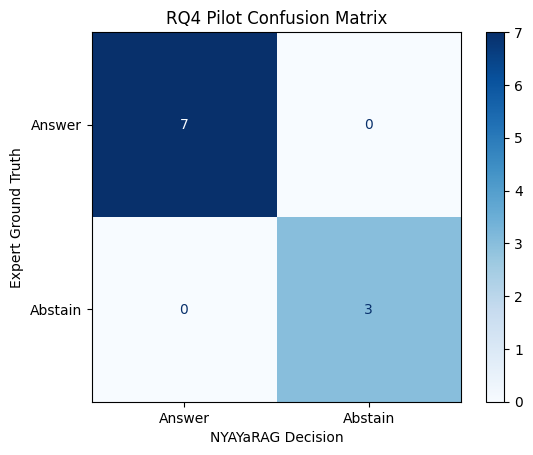


Confusion-matrix counts
True negatives — correct answers     : 7
False positives — false abstentions  : 0
False negatives — unsafe answers     : 0
True positives — correct abstentions : 3


In [ ]:
# ============================================================
# RQ4 PILOT CONFUSION MATRIX
# Positive class = INSUFFICIENT_EVIDENCE / ABSTAIN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)

rq4_results = final_decision_check.copy()

# Convert expert and model labels to binary values:
# 0 = ANSWER
# 1 = ABSTAIN / INSUFFICIENT_EVIDENCE

y_true = rq4_results["answerability_label"].map(
    {
        "answerable": 0,
        "insufficient_evidence": 1,
    }
)

y_pred = rq4_results["model_decision"].map(
    {
        "ANSWER": 0,
        "INSUFFICIENT_EVIDENCE": 1,
    }
)

assert y_true.notna().all(), "Unexpected expert answerability label found."
assert y_pred.notna().all(), "Unexpected model decision found."

# Rows = actual class; columns = predicted class
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

print("=" * 76)
print("RQ4 PILOT CONFUSION MATRIX")
print("=" * 76)
print("Positive class: Abstain / Insufficient Evidence")
print()
print(pd.DataFrame(
    cm,
    index=[
        "Actual: Answerable",
        "Actual: Insufficient Evidence",
    ],
    columns=[
        "Predicted: Answer",
        "Predicted: Abstain",
    ],
))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Answer",
        "Abstain",
    ],
)

display.plot(
    values_format="d",
    cmap="Blues",
)

plt.title("RQ4 Pilot Confusion Matrix")
plt.xlabel("NYAYaRAG Decision")
plt.ylabel("Expert Ground Truth")
plt.show()

print("\nConfusion-matrix counts")
print(f"True negatives — correct answers     : {tn}")
print(f"False positives — false abstentions  : {fp}")
print(f"False negatives — unsafe answers     : {fn}")
print(f"True positives — correct abstentions : {tp}")

In [ ]:
# ============================================================
# RQ4 PILOT ABSTENTION METRICS
# ============================================================

total = len(y_true)

accuracy = (tp + tn) / total

abstention_precision = precision_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

abstention_recall = recall_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

abstention_f1 = f1_score(
    y_true,
    y_pred,
    pos_label=1,
    zero_division=0,
)

correct_abstention_rate = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

false_answer_rate = (
    fn / (tp + fn)
    if (tp + fn) > 0
    else 0
)

false_abstention_rate = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else 0
)

print("=" * 76)
print("RQ4 PILOT ABSTENTION METRICS")
print("=" * 76)
print(f"Questions evaluated          : {total}")
print(f"Overall decision accuracy    : {accuracy:.3f}")
print(f"Correct-abstention rate      : {correct_abstention_rate:.3f}")
print(f"Abstention precision         : {abstention_precision:.3f}")
print(f"Abstention recall            : {abstention_recall:.3f}")
print(f"Abstention F1-score          : {abstention_f1:.3f}")
print(f"False-answer rate            : {false_answer_rate:.3f}")
print(f"False-abstention rate        : {false_abstention_rate:.3f}")

RQ4 PILOT ABSTENTION METRICS
Questions evaluated          : 10
Overall decision accuracy    : 1.000
Correct-abstention rate      : 1.000
Abstention precision         : 1.000
Abstention recall            : 1.000
Abstention F1-score          : 1.000
False-answer rate            : 0.000
False-abstention rate        : 0.000
